In [150]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/osheenvishnoi/amazon-ecommerce-sales-data/amazon_ecommerce_1M.csv


# E-Commerce Customer Intelligence and Analytics System

### Data Analytics and Machine Learning Project

**Student:** Osheen Vishnoi  
**Roll No.:** 2401530100102  
**Section:** CSE 3-B  
**College:** Lloyd Institute of Engineering and Technology  
**Session:** 2026–27

---

### Project Overview

This project analyzes e-commerce customer and transaction data to understand
sales performance, customer behavior, customer segmentation, churn,
customer lifetime value, and product recommendations.

The project uses Python, Pandas, NumPy, Matplotlib, Seaborn, and Scikit-learn
for data analysis and machine learning.

In [151]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [152]:
import os

for dirname, _, filenames in os.walk('/kaggle/input/datasets/osheenvishnoi/amazon-ecommerce-sales-data'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/osheenvishnoi/amazon-ecommerce-sales-data/amazon_ecommerce_1M.csv


In [153]:
file_path = "/kaggle/input/datasets/osheenvishnoi/amazon-ecommerce-sales-data/amazon_ecommerce_1M.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [154]:
df.head()

,user_id,product_id,category,subcategory,brand,price,discount,final_price,rating,review_count,stock,seller_id,seller_rating,purchase_date,shipping_time_days,location,device,payment_method,is_returned,delivery_status
0,U356787,P39256,Electronics,Mobile,H&M,33090.51,10.46,29629.31,4.9,43,71,S2679,4.3,2025-03-04,6,Bangalore,Tablet,UPI,True,Returned
1,U198246,P38657,Sports,Outdoor,Samsung,9368.97,5.32,8870.73,3.9,13,119,S9279,4.9,2025-12-12,1,Delhi,Tablet,UPI,True,Returned
2,U539898,P38893,Sports,Fitness,H&M,14756.85,26.00,10919.43,4.2,46,229,S5557,4.9,2024-04-25,1,Chennai,Mobile App,Credit Card,True,Returned
3,U325772,P54118,Beauty,Makeup,Sony,668.83,24.81,502.91,3.8,6,52,S2519,3.1,2025-12-18,2,Mumbai,Web,UPI,False,In Transit
4,U865179,P70217,Home,Decor,Sony,10881.29,48.63,5589.58,4.0,48,274,S3045,2.6,2024-05-16,5,Delhi,Web,UPI,False,Delayed


In [155]:
df.shape

(1000000, 20)

In [156]:
df.columns

Index(['user_id', 'product_id', 'category', 'subcategory', 'brand', 'price',
       'discount', 'final_price', 'rating', 'review_count', 'stock',
       'seller_id', 'seller_rating', 'purchase_date', 'shipping_time_days',
       'location', 'device', 'payment_method', 'is_returned',
       'delivery_status'],
      dtype='object')

In [157]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 20 columns):
 #   Column              Non-Null Count    Dtype  
---  ------              --------------    -----  
 0   user_id             1000000 non-null  object 
 1   product_id          1000000 non-null  object 
 2   category            1000000 non-null  object 
 3   subcategory         1000000 non-null  object 
 4   brand               1000000 non-null  object 
 5   price               1000000 non-null  float64
 6   discount            1000000 non-null  float64
 7   final_price         1000000 non-null  float64
 8   rating              1000000 non-null  float64
 9   review_count        1000000 non-null  int64  
 10  stock               1000000 non-null  int64  
 11  seller_id           1000000 non-null  object 
 12  seller_rating       1000000 non-null  float64
 13  purchase_date       1000000 non-null  object 
 14  shipping_time_days  1000000 non-null  int64  
 15  location        

In [158]:
df.isnull().sum()

user_id               0
product_id            0
category              0
subcategory           0
brand                 0
price                 0
discount              0
final_price           0
rating                0
review_count          0
stock                 0
seller_id             0
seller_rating         0
purchase_date         0
shipping_time_days    0
location              0
device                0
payment_method        0
is_returned           0
delivery_status       0
dtype: int64

In [159]:
df.duplicated().sum()

np.int64(0)

In [160]:
df.describe()

,price,discount,final_price,rating,review_count,stock,seller_rating,shipping_time_days
count,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000
mean,13224.119093,28.996161,9938.876985,3.927226,32.626704,250.023345,3.750030,3.166389
std,18079.626921,14.681077,14271.885557,0.519443,43.382201,144.567038,0.722092,1.674178
min,200.030000,5.000000,101.460000,1.500000,0.000000,0.000000,2.500000,1.000000
25%,2700.147500,16.910000,1705.930000,3.600000,10.000000,125.000000,3.100000,2.000000
50%,4971.830000,28.070000,3790.795000,3.900000,20.000000,250.000000,3.800000,3.000000
75%,14134.482500,39.240000,10384.440000,4.300000,39.000000,375.000000,4.400000,5.000000
max,79999.700000,70.000000,75831.110000,5.000000,3408.000000,500.000000,5.000000,6.000000


In [161]:
print("Unique customers:", df['user_id'].nunique())
print("Unique products:", df['product_id'].nunique())
print("Unique categories:", df['category'].nunique())

Unique customers: 603815
Unique products: 89999
Unique categories: 5


In [162]:
df['purchase_date'] = pd.to_datetime(df['purchase_date'])

In [163]:
print("Start date:", df['purchase_date'].min())
print("End date:", df['purchase_date'].max())

Start date: 2024-03-31 00:00:00
End date: 2026-03-31 00:00:00


# 2. Data Cleaning and Preprocessing

The dataset contains 1,000,000 e-commerce transaction records and 20 attributes.
Initial inspection shows that there are no missing values or duplicate records.
Therefore, preprocessing focuses on data type conversion, validation of numerical
values, and preparation of variables required for customer analytics and machine
learning.

In [164]:
print("Missing dates:", df['purchase_date'].isna().sum())
print("Minimum date:", df['purchase_date'].min())
print("Maximum date:", df['purchase_date'].max())

Missing dates: 0
Minimum date: 2024-03-31 00:00:00
Maximum date: 2026-03-31 00:00:00


In [165]:
print("Negative prices:", (df['price'] < 0).sum())
print("Negative discounts:", (df['discount'] < 0).sum())
print("Negative final prices:", (df['final_price'] < 0).sum())
print("Negative shipping days:", (df['shipping_time_days'] < 0).sum())

Negative prices: 0
Negative discounts: 0
Negative final prices: 0
Negative shipping days: 0


In [166]:
print("Minimum discount:", df['discount'].min())
print("Maximum discount:", df['discount'].max())

Minimum discount: 5.0
Maximum discount: 70.0


In [167]:
print("Minimum rating:", df['rating'].min())
print("Maximum rating:", df['rating'].max())

print("Invalid ratings:", 
      ((df['rating'] < 1) | (df['rating'] > 5)).sum())

Minimum rating: 1.5
Maximum rating: 5.0
Invalid ratings: 0


In [168]:
calculated_price = df['price'] * (1 - df['discount'] / 100)

difference = (df['final_price'] - calculated_price).abs()

print("Maximum difference:", difference.max())
print("Average difference:", difference.mean())

Maximum difference: 3.986772000003839
Average difference: 0.3304649197490017


In [169]:
print(df['category'].value_counts())

category
Home           200922
Electronics    200038
Sports         199889
Clothing       199824
Beauty         199327
Name: count, dtype: int64


In [170]:
print(df['device'].value_counts())

device
Mobile App    333637
Web           333297
Tablet        333066
Name: count, dtype: int64


In [171]:
print(df['payment_method'].value_counts())

payment_method
Cash on Delivery    250388
Credit Card         250324
UPI                 249951
Debit Card          249337
Name: count, dtype: int64


In [172]:
print(df['delivery_status'].value_counts())

delivery_status
Delivered     295234
Delayed       294983
In Transit    293793
Returned      115990
Name: count, dtype: int64


In [173]:
print(df['is_returned'].value_counts())

is_returned
False    884010
True     115990
Name: count, dtype: int64


In [174]:
customer_purchase_counts = df['user_id'].value_counts()

print(customer_purchase_counts.describe())

count    603815.000000
mean          1.656136
std           0.869229
min           1.000000
25%           1.000000
50%           1.000000
75%           2.000000
max           9.000000
Name: count, dtype: float64


In [175]:
print("Customers with only 1 purchase:",
      (customer_purchase_counts == 1).sum())

print("Customers with more than 1 purchase:",
      (customer_purchase_counts > 1).sum())

Customers with only 1 purchase: 329745
Customers with more than 1 purchase: 274070


In [176]:
df['revenue'] = df['final_price']

In [177]:
print("Total Revenue:", df['revenue'].sum())
print("Average Transaction Value:", df['revenue'].mean())

Total Revenue: 9938876984.9
Average Transaction Value: 9938.8769849


In [178]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 1000000
Columns: 21


# 3. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand customer behavior,
sales patterns, product performance, payment preferences, and return trends.

The analysis helps identify important patterns before applying customer
segmentation and machine learning techniques.

In [179]:
monthly_revenue = (
    df.groupby(df['purchase_date'].dt.to_period('M'))['revenue']
      .sum()
      .reset_index()
)

monthly_revenue['purchase_date'] = monthly_revenue['purchase_date'].astype(str)

print(monthly_revenue.head())
print(monthly_revenue.tail())

  purchase_date       revenue
0       2024-03  1.388802e+07
1       2024-04  4.096292e+08
2       2024-05  4.207856e+08
3       2024-06  4.051715e+08
4       2024-07  4.217882e+08
   purchase_date       revenue
20       2025-11  4.056734e+08
21       2025-12  4.281423e+08
22       2026-01  4.214767e+08
23       2026-02  3.812453e+08
24       2026-03  4.236515e+08


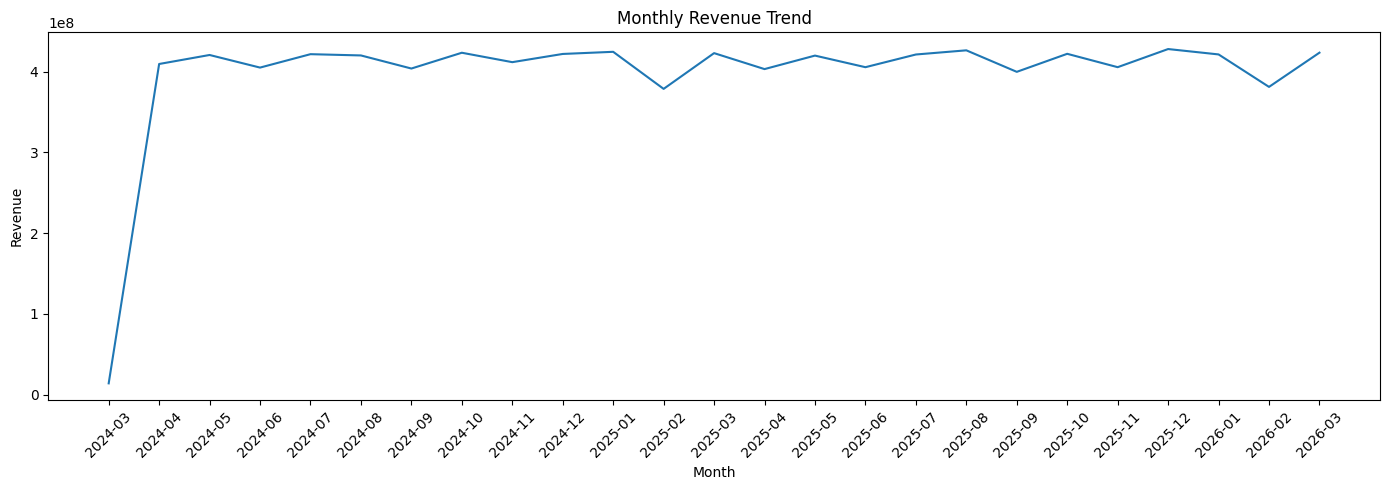

In [180]:
plt.figure(figsize=(14, 5))

plt.plot(
    monthly_revenue['purchase_date'],
    monthly_revenue['revenue']
)

plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [181]:
category_revenue = (
    df.groupby('category')['revenue']
      .sum()
      .sort_values(ascending=False)
)

print(category_revenue)

category
Electronics    6.579048e+09
Home           1.529978e+09
Sports         1.124849e+09
Beauty         3.759517e+08
Clothing       3.290504e+08
Name: revenue, dtype: float64


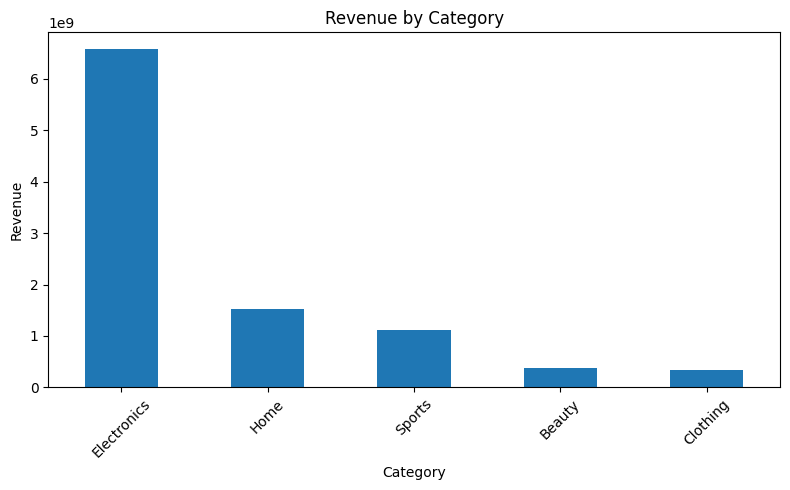

In [182]:
plt.figure(figsize=(8, 5))

category_revenue.plot(kind='bar')

plt.title('Revenue by Category')
plt.xlabel('Category')
plt.ylabel('Revenue')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [183]:
payment_counts = df['payment_method'].value_counts()

print(payment_counts)

payment_method
Cash on Delivery    250388
Credit Card         250324
UPI                 249951
Debit Card          249337
Name: count, dtype: int64


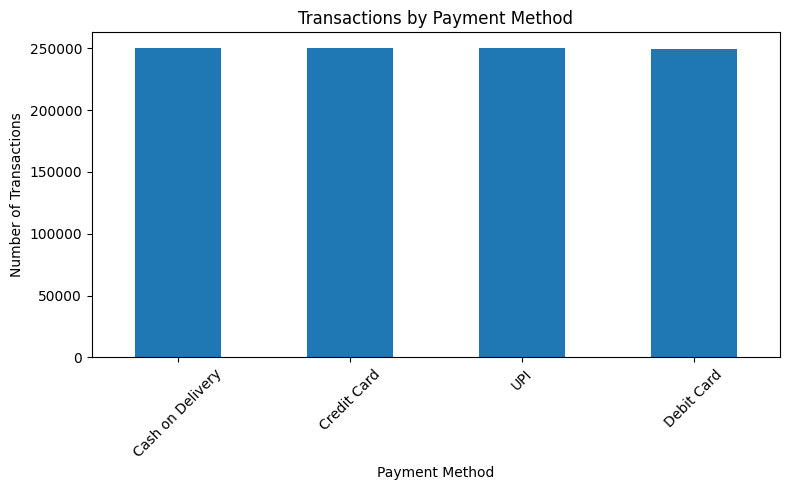

In [184]:
plt.figure(figsize=(8, 5))

payment_counts.plot(kind='bar')

plt.title('Transactions by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Number of Transactions')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [185]:
return_counts = df['is_returned'].value_counts()

print(return_counts)

is_returned
False    884010
True     115990
Name: count, dtype: int64


In [186]:
return_rate = df['is_returned'].mean() * 100

print(f"Return Rate: {return_rate:.2f}%")

Return Rate: 11.60%


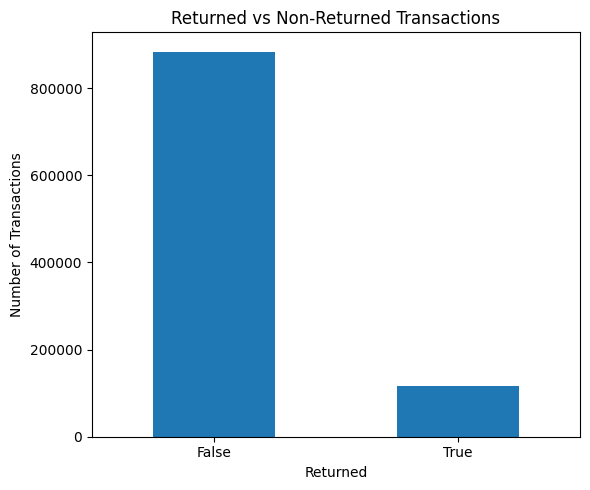

In [187]:
plt.figure(figsize=(6, 5))

return_counts.plot(kind='bar')

plt.title('Returned vs Non-Returned Transactions')
plt.xlabel('Returned')
plt.ylabel('Number of Transactions')

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 4. Product and Customer Analysis

This stage analyzes product performance and customer purchasing behavior.
The analysis identifies high-revenue products and helps prepare the data
for customer segmentation using RFM analysis.

In [188]:
product_revenue = (
    df.groupby('product_id')['revenue']
      .sum()
      .sort_values(ascending=False)
)

print("Top 10 Products by Revenue:")
print(product_revenue.head(10))

Top 10 Products by Revenue:
product_id
P46010    456149.10
P17701    452145.90
P38580    434172.15
P95005    421329.88
P52877    416852.68
P35567    413217.21
P77873    412930.05
P75763    409451.03
P12702    409101.42
P39049    405767.85
Name: revenue, dtype: float64


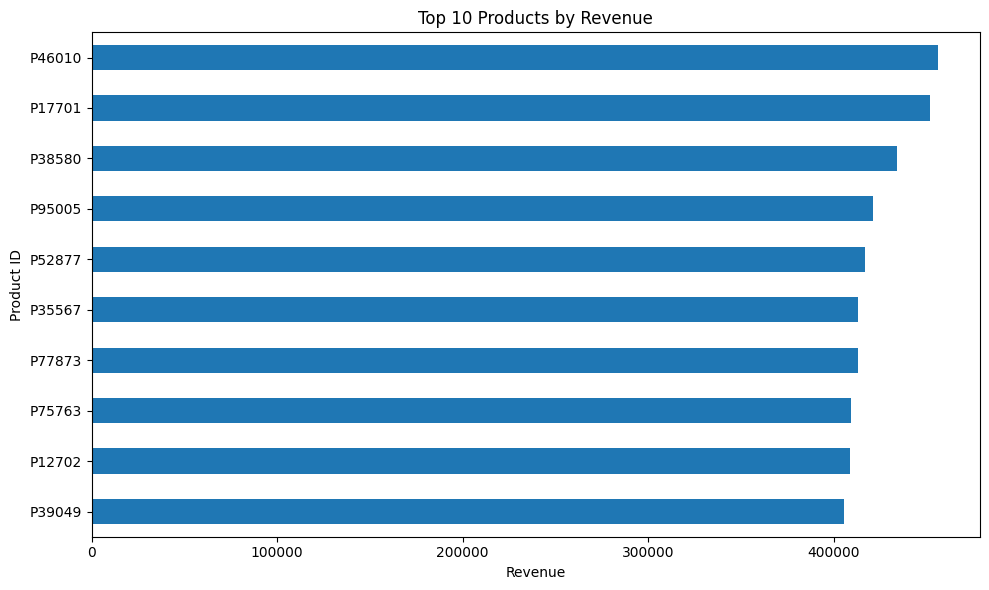

In [189]:
top_products = product_revenue.head(10)

plt.figure(figsize=(10, 6))

top_products.sort_values().plot(kind='barh')

plt.title('Top 10 Products by Revenue')
plt.xlabel('Revenue')
plt.ylabel('Product ID')

plt.tight_layout()
plt.show()

In [190]:
product_transactions = (
    df['product_id']
      .value_counts()
      .head(10)
)

print("Top 10 Products by Number of Transactions:")
print(product_transactions)

Top 10 Products by Number of Transactions:
product_id
P96731    28
P11002    27
P50882    27
P43630    27
P13897    27
P96698    26
P51710    26
P82286    26
P26688    26
P12723    26
Name: count, dtype: int64


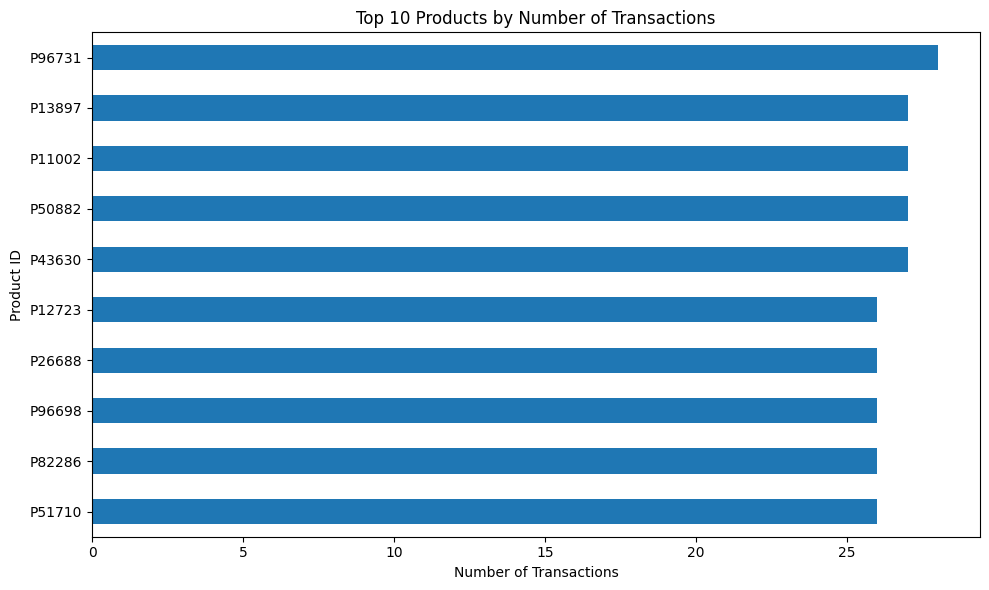

In [191]:
plt.figure(figsize=(10, 6))

product_transactions.sort_values().plot(kind='barh')

plt.title('Top 10 Products by Number of Transactions')
plt.xlabel('Number of Transactions')
plt.ylabel('Product ID')

plt.tight_layout()
plt.show()

In [192]:
customer_spending = (
    df.groupby('user_id')['revenue']
      .sum()
      .sort_values(ascending=False)
)

print("Top 10 Customers by Spending:")
print(customer_spending.head(10))

Top 10 Customers by Spending:
user_id
U434268    229853.10
U902761    207234.79
U454661    199875.10
U384705    195983.73
U706383    195247.80
U978563    192137.94
U746513    188840.50
U224240    186945.13
U471344    181008.08
U877443    180892.29
Name: revenue, dtype: float64


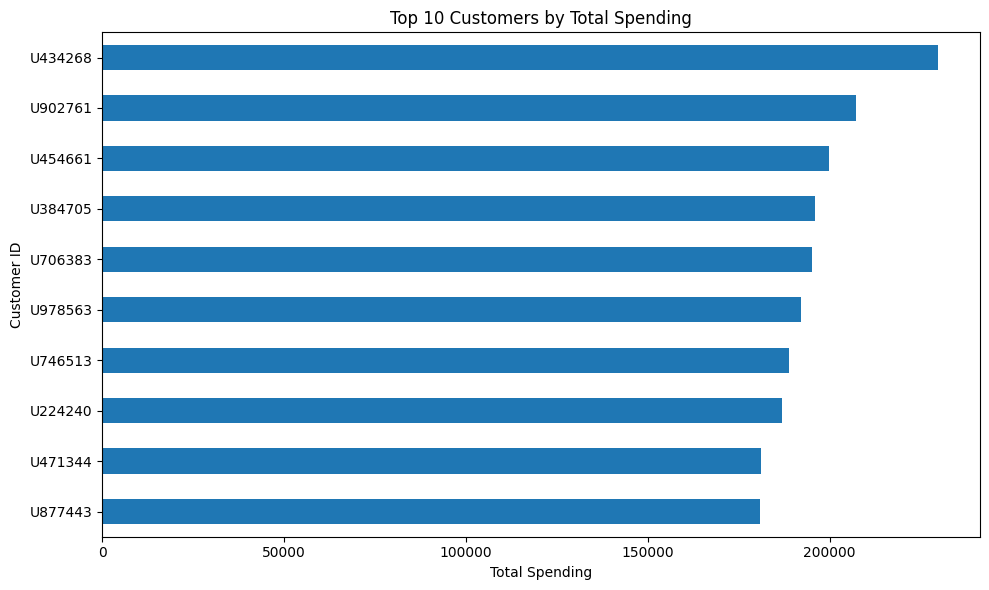

In [193]:
plt.figure(figsize=(10, 6))

customer_spending.head(10).sort_values().plot(kind='barh')

plt.title('Top 10 Customers by Total Spending')
plt.xlabel('Total Spending')
plt.ylabel('Customer ID')

plt.tight_layout()
plt.show()

# 5. RFM Customer Segmentation

RFM analysis is used to quantify customer purchasing behavior using
Recency, Frequency, and Monetary value.

Recency measures how recently a customer purchased.
Frequency measures the number of transactions.
Monetary measures the total amount spent by the customer.

These customer-level features will later be used for K-Means clustering.

In [194]:
 analysis_date = df['purchase_date'].max() + pd.Timedelta(days=1)

print("Analysis Date:", analysis_date)

Analysis Date: 2026-04-01 00:00:00


In [195]:
rfm = df.groupby('user_id').agg(
    Recency=('purchase_date', lambda x: (analysis_date - x.max()).days),
    Frequency=('user_id', 'count'),
    Monetary=('revenue', 'sum')
)

print(rfm.head())

         Recency  Frequency  Monetary
user_id                              
U100001      195          2   7551.46
U100003      515          3  12966.04
U100004      323          1  66406.56
U100005      452          1    816.17
U100009      175          1   9374.64


In [196]:
print("RFM shape:", rfm.shape)
print()
print(rfm.describe())

RFM shape: (603815, 3)

             Recency      Frequency       Monetary
count  603815.000000  603815.000000  603815.000000
mean      299.737314       1.656136   16460.135944
std       204.750487       0.869229   20291.108065
min         1.000000       1.000000     103.040000
25%       121.000000       1.000000    2830.190000
50%       270.000000       1.000000    8162.180000
75%       460.000000       2.000000   20924.710000
max       731.000000       9.000000  229853.100000


In [197]:
print("Missing values:")
print(rfm.isnull().sum())

Missing values:
Recency      0
Frequency    0
Monetary     0
dtype: int64


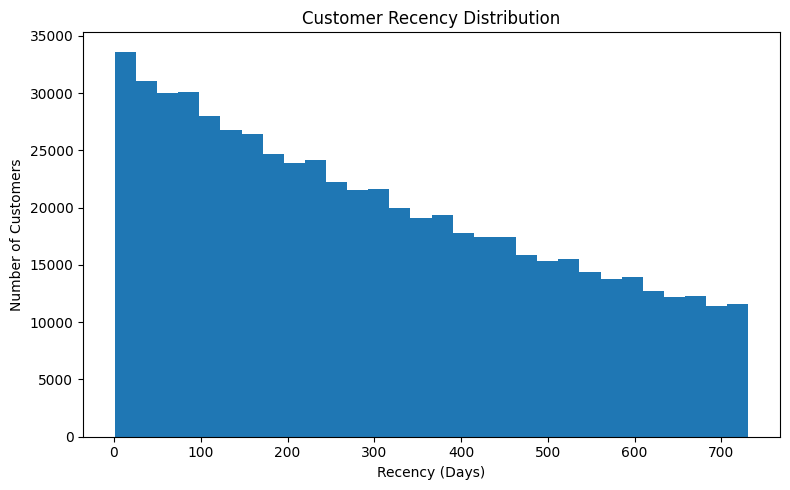

In [198]:
plt.figure(figsize=(8, 5))

plt.hist(rfm['Recency'], bins=30)

plt.title('Customer Recency Distribution')
plt.xlabel('Recency (Days)')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()

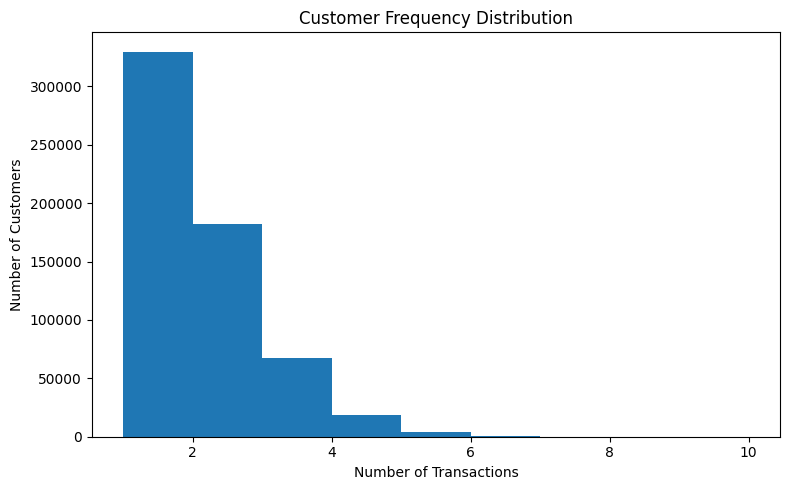

In [199]:
plt.figure(figsize=(8, 5))

plt.hist(rfm['Frequency'], bins=range(1, rfm['Frequency'].max() + 2))

plt.title('Customer Frequency Distribution')
plt.xlabel('Number of Transactions')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()

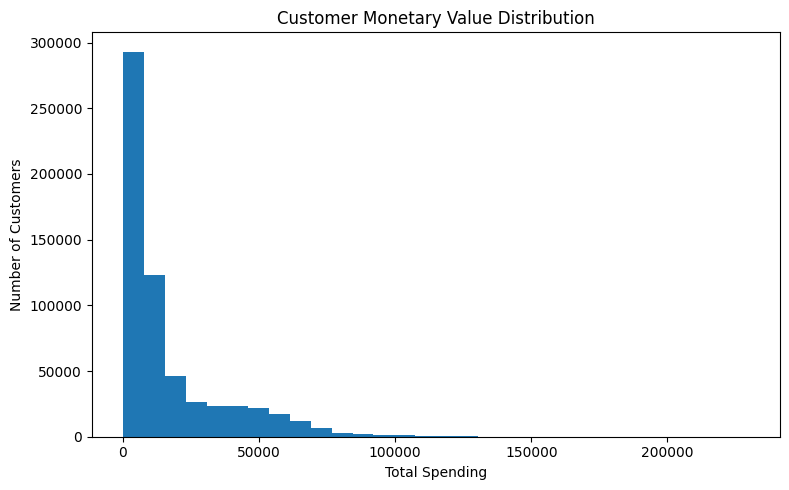

In [200]:
plt.figure(figsize=(8, 5))

plt.hist(rfm['Monetary'], bins=30)

plt.title('Customer Monetary Value Distribution')
plt.xlabel('Total Spending')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()

# 6. RFM Scoring

RFM scores are assigned on a scale of 1 to 5 using customer
percentiles.

For Recency, a lower value indicates more recent activity and
therefore receives a higher score.

For Frequency and Monetary value, higher values indicate stronger
customer engagement and therefore receive higher scores.

In [201]:
rfm['R_Score'] = pd.qcut(
    rfm['Recency'],
    5,
    labels=[5, 4, 3, 2, 1],
    duplicates='drop'
)

rfm['F_Score'] = pd.qcut(
    rfm['Frequency'].rank(method='first'),
    5,
    labels=[1, 2, 3, 4, 5]
)

rfm['M_Score'] = pd.qcut(
    rfm['Monetary'].rank(method='first'),
    5,
    labels=[1, 2, 3, 4, 5]
)

print(rfm.head())

         Recency  Frequency  Monetary R_Score F_Score M_Score
user_id                                                      
U100001      195          2   7551.46       4       3       3
U100003      515          3  12966.04       1       5       4
U100004      323          1  66406.56       3       1       5
U100005      452          1    816.17       2       1       1
U100009      175          1   9374.64       4       1       3


In [202]:
rfm['RFM_Score'] = (
    rfm['R_Score'].astype(int) +
    rfm['F_Score'].astype(int) +
    rfm['M_Score'].astype(int)
)

print(rfm.head())

         Recency  Frequency  Monetary R_Score F_Score M_Score  RFM_Score
user_id                                                                 
U100001      195          2   7551.46       4       3       3         10
U100003      515          3  12966.04       1       5       4         10
U100004      323          1  66406.56       3       1       5          9
U100005      452          1    816.17       2       1       1          4
U100009      175          1   9374.64       4       1       3          8


In [203]:
print(rfm['RFM_Score'].describe())

count    603815.000000
mean          9.001659
std           3.102611
min           3.000000
25%           7.000000
50%           9.000000
75%          11.000000
max          15.000000
Name: RFM_Score, dtype: float64


In [204]:
print(rfm['RFM_Score'].value_counts().sort_index())

RFM_Score
3     12580
4     31022
5     48712
6     57384
7     63884
8     63551
9     60799
10    57751
11    57526
12    53104
13    46290
14    34636
15    16576
Name: count, dtype: int64


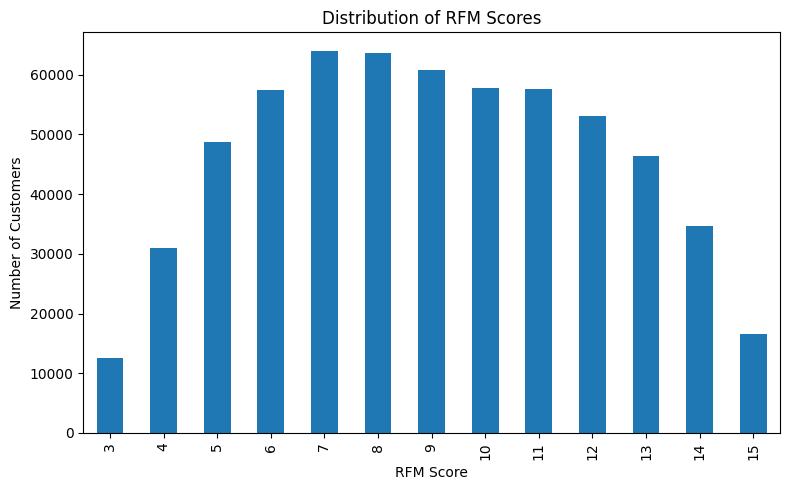

In [205]:
plt.figure(figsize=(8, 5))

rfm['RFM_Score'].value_counts().sort_index().plot(kind='bar')

plt.title('Distribution of RFM Scores')
plt.xlabel('RFM Score')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()

# 7. K-Means Customer Segmentation

K-Means clustering is used to group customers with similar purchasing
behavior.

The clustering model uses Recency, Frequency, and Monetary features.
Log transformation is applied to reduce the effect of highly skewed
customer spending, followed by standardization so that all features
have comparable scales.

In [206]:
rfm_features = rfm[['Recency', 'Frequency', 'Monetary']].copy()

print(rfm_features.head())

         Recency  Frequency  Monetary
user_id                              
U100001      195          2   7551.46
U100003      515          3  12966.04
U100004      323          1  66406.56
U100005      452          1    816.17
U100009      175          1   9374.64


In [207]:
rfm_log = np.log1p(rfm_features)

print(rfm_log.head())

          Recency  Frequency   Monetary
user_id                                
U100001  5.278115   1.098612   8.929629
U100003  6.246107   1.386294   9.470166
U100004  5.780744   0.693147  11.103566
U100005  6.115892   0.693147   6.705847
U100009  5.170484   0.693147   9.145870


In [208]:
scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm_log)

print("Scaled data shape:", rfm_scaled.shape)

Scaled data shape: (603815, 3)


In [209]:
sample_size = 50000

rng = np.random.RandomState(42)

sample_indices = rng.choice(
    rfm_scaled.shape[0],
    size=sample_size,
    replace=False
)

rfm_sample = rfm_scaled[sample_indices]

print("Sample size:", rfm_sample.shape)

Sample size: (50000, 3)


In [210]:
inertia = []

for k in range(2, 8):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(rfm_sample)
    
    inertia.append(kmeans.inertia_)

print("Inertia values:")
for k, value in zip(range(2, 8), inertia):
    print(f"K = {k}: {value:.2f}")

Inertia values:
K = 2: 91628.40
K = 3: 71955.66
K = 4: 55729.35
K = 5: 46750.16
K = 6: 40293.51
K = 7: 36072.85


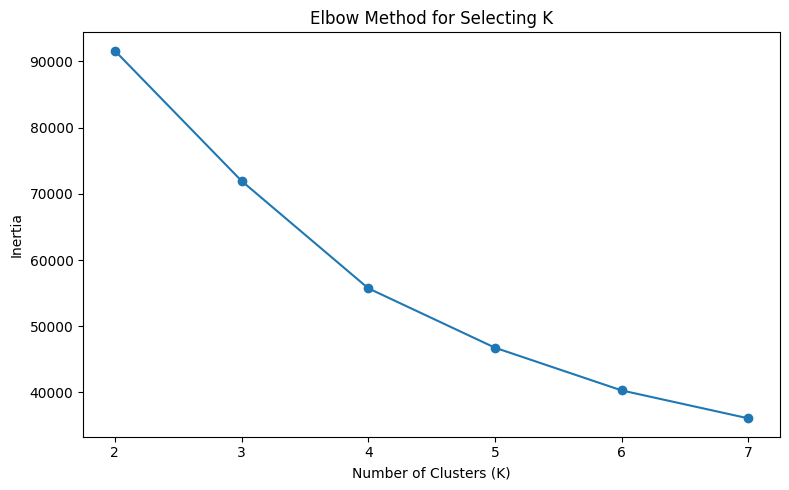

In [211]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 8),
    inertia,
    marker='o'
)

plt.title('Elbow Method for Selecting K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')

plt.xticks(range(2, 8))
plt.tight_layout()
plt.show()

In [212]:
silhouette_scores = []

for k in range(2, 8):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    cluster_labels = kmeans.fit_predict(rfm_sample)
    
    score = silhouette_score(
        rfm_sample,
        cluster_labels
    )
    
    silhouette_scores.append(score)

print("Silhouette Scores:")

for k, score in zip(range(2, 8), silhouette_scores):
    print(f"K = {k}: {score:.4f}")

Silhouette Scores:
K = 2: 0.3683
K = 3: 0.3496
K = 4: 0.3337
K = 5: 0.3387
K = 6: 0.3551
K = 7: 0.3478


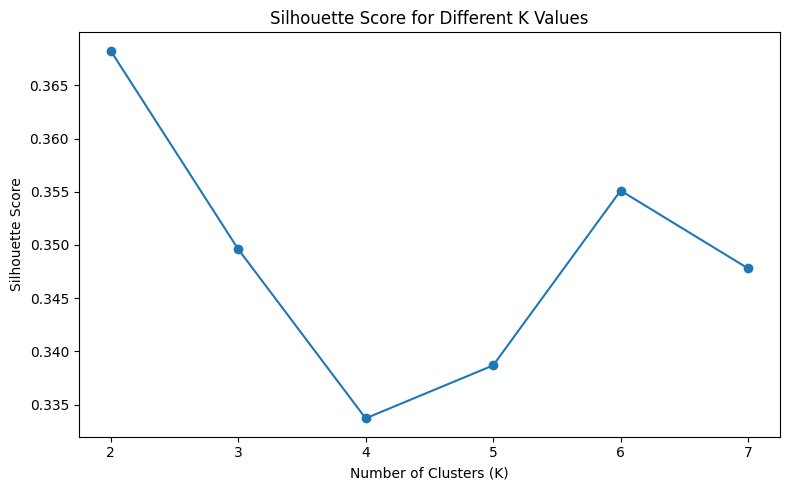

In [213]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 8),
    silhouette_scores,
    marker='o'
)

plt.title('Silhouette Score for Different K Values')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')

plt.xticks(range(2, 8))
plt.tight_layout()
plt.show()

# 8. Comparing Candidate K-Means Solutions

K-Means models with different numbers of clusters are compared using
cluster size and average Recency, Frequency, and Monetary values.

This helps select a cluster solution that is both quantitatively
reasonable and meaningful for customer behavior analysis.

In [214]:
candidate_results = {}

for k in [2, 4, 6]:
    
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    labels = model.fit_predict(rfm_scaled)
    
    temp = rfm_features.copy()
    temp['Cluster'] = labels
    
    profile = temp.groupby('Cluster').agg(
        Customers=('Recency', 'size'),
        Avg_Recency=('Recency', 'mean'),
        Avg_Frequency=('Frequency', 'mean'),
        Avg_Monetary=('Monetary', 'mean')
    ).round(2)
    
    candidate_results[k] = profile
    
    print(f"\n========== K = {k} ==========")
    print(profile)


========== K = 2 ==========
         Customers  Avg_Recency  Avg_Frequency  Avg_Monetary
Cluster                                                     
0           348079       382.23           1.10       8360.91
1           255736       187.46           2.42      27483.89

========== K = 4 ==========
         Customers  Avg_Recency  Avg_Frequency  Avg_Monetary
Cluster                                                     
0            78850        32.89           2.02      18703.52
1           133987       400.68           1.00      19828.12
2           186969       380.97           1.08       2033.32
3           204009       262.13           2.48      26602.88

========== K = 6 ==========
         Customers  Avg_Recency  Avg_Frequency  Avg_Monetary
Cluster                                                     
0           125742       413.35           1.00      20669.70
1            55327        63.36           1.08       5414.35
2           152080       432.36           1.00       2010.7

# 9. Final K-Means Customer Segmentation

Based on the comparison of different cluster configurations, four
clusters are used for the final customer segmentation model.

The model is trained on the standardized RFM features of all customers.

In [215]:
final_kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

rfm['Cluster'] = final_kmeans.fit_predict(rfm_scaled)

print("Final K-Means model completed.")
print("Number of customers:", len(rfm))

Final K-Means model completed.
Number of customers: 603815


In [216]:
cluster_profile = rfm.groupby('Cluster').agg(
    Customers=('Recency', 'size'),
    Avg_Recency=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Monetary=('Monetary', 'mean')
).round(2)

print(cluster_profile)

         Customers  Avg_Recency  Avg_Frequency  Avg_Monetary
Cluster                                                     
0            78850        32.89           2.02      18703.52
1           133987       400.68           1.00      19828.12
2           186969       380.97           1.08       2033.32
3           204009       262.13           2.48      26602.88


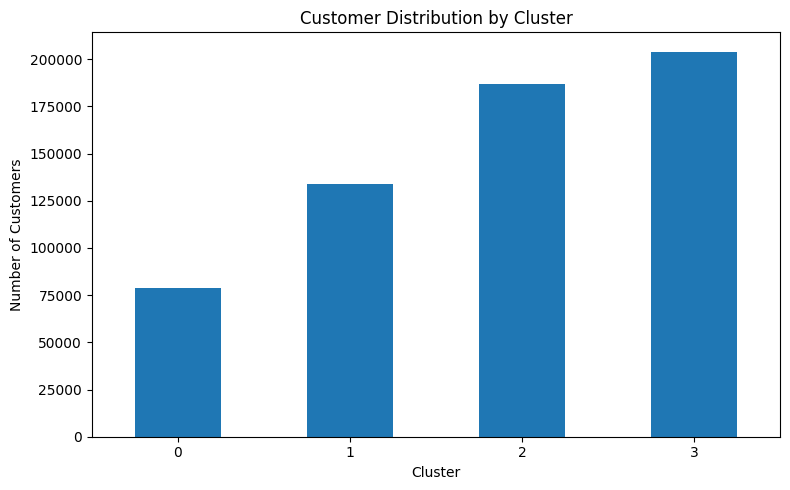

In [217]:
plt.figure(figsize=(8, 5))

cluster_profile['Customers'].plot(kind='bar')

plt.title('Customer Distribution by Cluster')
plt.xlabel('Cluster')
plt.ylabel('Number of Customers')

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 10. Customer Segment Profiling

The K-Means clusters are interpreted using their average Recency,
Frequency, and Monetary values. Each cluster is assigned a descriptive
business segment name based on its observed purchasing behavior.

In [218]:
cluster_names = {
    0: 'Recent Active Customers',
    1: 'At-Risk High-Value Customers',
    2: 'Dormant Low-Value Customers',
    3: 'Frequent High-Value Customers'
}

rfm['Segment'] = rfm['Cluster'].map(cluster_names)

print(rfm[['Recency', 'Frequency', 'Monetary', 'Cluster', 'Segment']].head())

         Recency  Frequency  Monetary  Cluster                        Segment
user_id                                                                      
U100001      195          2   7551.46        3  Frequent High-Value Customers
U100003      515          3  12966.04        3  Frequent High-Value Customers
U100004      323          1  66406.56        1   At-Risk High-Value Customers
U100005      452          1    816.17        2    Dormant Low-Value Customers
U100009      175          1   9374.64        1   At-Risk High-Value Customers


In [219]:
segment_profile = rfm.groupby('Segment').agg(
    Customers=('Recency', 'size'),
    Avg_Recency=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Monetary=('Monetary', 'mean')
).round(2)

segment_profile['Customer_Percentage'] = (
    segment_profile['Customers'] / len(rfm) * 100
).round(2)

print(segment_profile)

                               Customers  Avg_Recency  Avg_Frequency  \
Segment                                                                
At-Risk High-Value Customers      133987       400.68           1.00   
Dormant Low-Value Customers       186969       380.97           1.08   
Frequent High-Value Customers     204009       262.13           2.48   
Recent Active Customers            78850        32.89           2.02   

                               Avg_Monetary  Customer_Percentage  
Segment                                                           
At-Risk High-Value Customers       19828.12                22.19  
Dormant Low-Value Customers         2033.32                30.96  
Frequent High-Value Customers      26602.88                33.79  
Recent Active Customers            18703.52                13.06  


In [220]:
segment_revenue = (
    rfm.groupby('Segment')['Monetary']
    .sum()
    .sort_values(ascending=False)
)

print("Total Revenue by Customer Segment:")
print(segment_revenue)

Total Revenue by Customer Segment:
Segment
Frequent High-Value Customers    5.427227e+09
At-Risk High-Value Customers     2.656710e+09
Recent Active Customers          1.474772e+09
Dormant Low-Value Customers      3.801677e+08
Name: Monetary, dtype: float64


In [221]:
segment_returns = (
    df[['user_id', 'is_returned']]
    .merge(
        rfm[['Segment']],
        left_on='user_id',
        right_index=True,
        how='left'
    )
    .groupby('Segment')['is_returned']
    .mean() * 100
)

segment_returns = segment_returns.round(2)

print("Return Rate by Customer Segment:")
print(segment_returns)

Return Rate by Customer Segment:
Segment
At-Risk High-Value Customers     11.42
Dormant Low-Value Customers      11.77
Frequent High-Value Customers    11.61
Recent Active Customers          11.49
Name: is_returned, dtype: float64


In [222]:
final_segment_summary = segment_profile.copy()

final_segment_summary['Total_Revenue'] = (
    segment_revenue
)

final_segment_summary['Return_Rate'] = (
    segment_returns
)

print(final_segment_summary)

                               Customers  Avg_Recency  Avg_Frequency  \
Segment                                                                
At-Risk High-Value Customers      133987       400.68           1.00   
Dormant Low-Value Customers       186969       380.97           1.08   
Frequent High-Value Customers     204009       262.13           2.48   
Recent Active Customers            78850        32.89           2.02   

                               Avg_Monetary  Customer_Percentage  \
Segment                                                            
At-Risk High-Value Customers       19828.12                22.19   
Dormant Low-Value Customers         2033.32                30.96   
Frequent High-Value Customers      26602.88                33.79   
Recent Active Customers            18703.52                13.06   

                               Total_Revenue  Return_Rate  
Segment                                                    
At-Risk High-Value Customers    2.6567

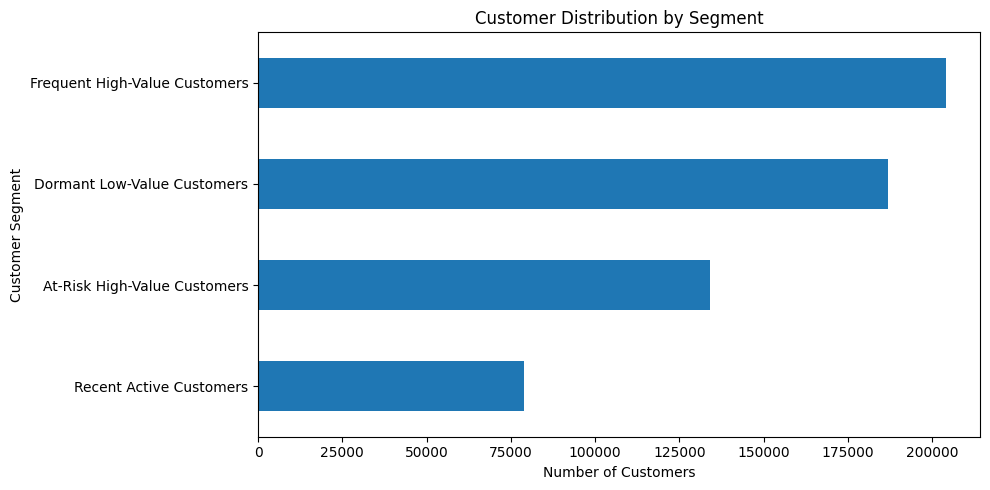

In [223]:
plt.figure(figsize=(10, 5))

segment_profile['Customers'].sort_values().plot(kind='barh')

plt.title('Customer Distribution by Segment')
plt.xlabel('Number of Customers')
plt.ylabel('Customer Segment')

plt.tight_layout()
plt.show()

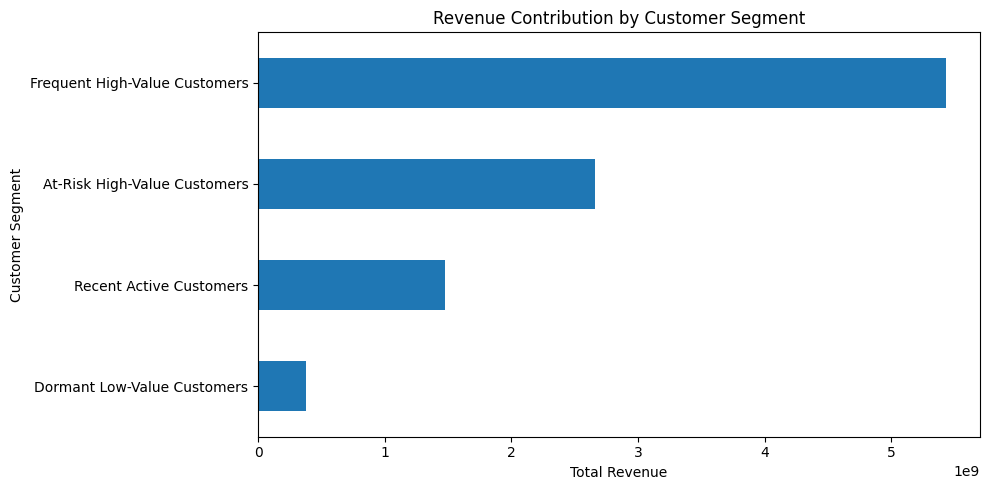

In [224]:
plt.figure(figsize=(10, 5))

segment_revenue.sort_values().plot(kind='barh')

plt.title('Revenue Contribution by Customer Segment')
plt.xlabel('Total Revenue')
plt.ylabel('Customer Segment')

plt.tight_layout()
plt.show()

# 11. Customer Churn Analysis

The dataset does not contain an explicit churn label. Therefore, churn
is defined using customer inactivity.

A customer with Recency greater than 180 days is classified as churned,
while a customer with Recency of 180 days or less is classified as active.

This rule provides a transparent behavioral definition of churn based
on the available purchase history.

In [225]:
rfm['Churn'] = np.where(
    rfm['Recency'] > 180,
    1,
    0
)

rfm['Churn_Label'] = rfm['Churn'].map({
    0: 'Active',
    1: 'Churned'
})

print(rfm['Churn_Label'].value_counts())

Churn_Label
Churned    388406
Active     215409
Name: count, dtype: int64


In [226]:
churn_rate = rfm['Churn'].mean() * 100

print(f"Overall Churn Rate: {churn_rate:.2f}%")

Overall Churn Rate: 64.33%


In [227]:
print(
    rfm.groupby('Churn_Label')
       .agg(
           Customers=('Recency', 'size'),
           Avg_Recency=('Recency', 'mean'),
           Avg_Frequency=('Frequency', 'mean'),
           Avg_Monetary=('Monetary', 'mean')
       )
       .round(2)
)

             Customers  Avg_Recency  Avg_Frequency  Avg_Monetary
Churn_Label                                                     
Active          215409        86.26           1.98      19727.04
Churned         388406       418.13           1.48      14648.32


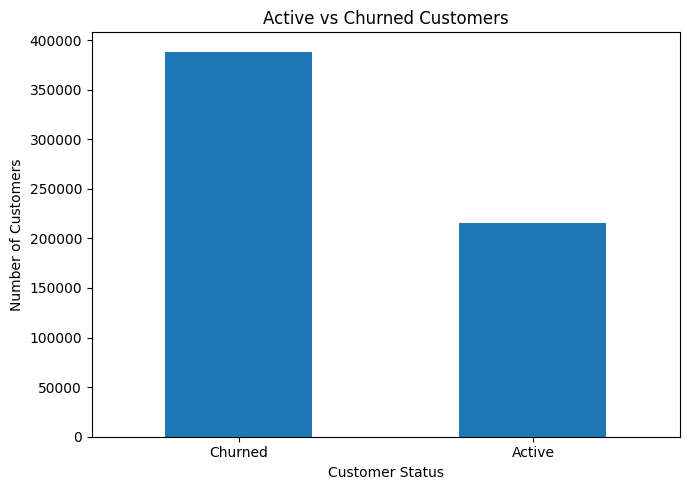

In [228]:
churn_counts = rfm['Churn_Label'].value_counts()

plt.figure(figsize=(7, 5))

churn_counts.plot(kind='bar')

plt.title('Active vs Churned Customers')
plt.xlabel('Customer Status')
plt.ylabel('Number of Customers')

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [229]:
segment_churn = (
    rfm.groupby('Segment')['Churn']
       .mean()
       .mul(100)
       .round(2)
       .sort_values(ascending=False)
)

print("Churn Rate by Customer Segment:")
print(segment_churn)

Churn Rate by Customer Segment:
Segment
At-Risk High-Value Customers     83.02
Dormant Low-Value Customers      79.66
Frequent High-Value Customers    62.85
Recent Active Customers           0.00
Name: Churn, dtype: float64


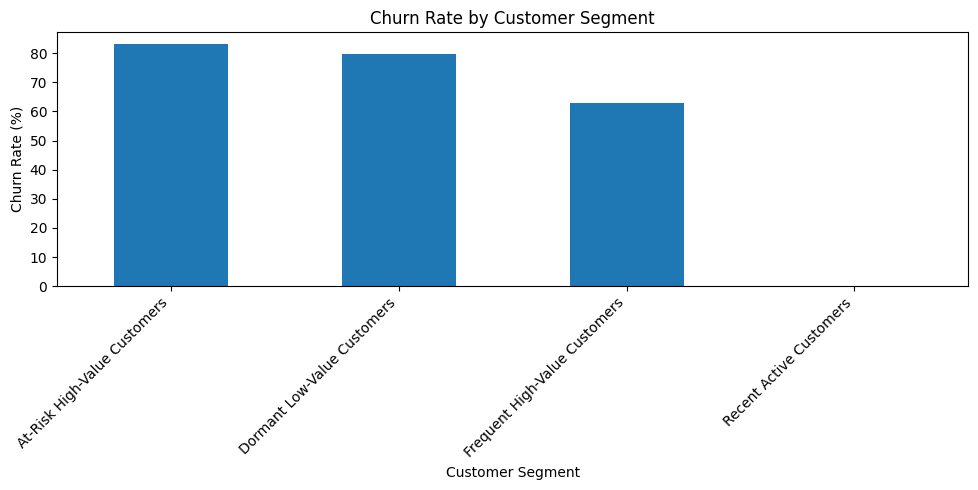

In [230]:
plt.figure(figsize=(10, 5))

segment_churn.plot(kind='bar')

plt.title('Churn Rate by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Churn Rate (%)')

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# 12. Churn Prediction Model

A machine learning model is developed to predict customer churn using
customer purchasing behavior.

The target variable is the churn label created from the 180-day
inactivity rule. Recency, Frequency, Monetary value, and RFM score are
used as customer behavior features.

In [231]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [232]:
X = rfm[
    ['Recency', 'Frequency', 'Monetary', 'RFM_Score']
]

y = rfm['Churn']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (603815, 4)
Target shape: (603815,)


In [233]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 483052
Testing samples: 120763


In [234]:
from sklearn.preprocessing import StandardScaler

scaler_churn = StandardScaler()

X_train_scaled = scaler_churn.fit_transform(X_train)
X_test_scaled = scaler_churn.transform(X_test)

print("Feature scaling completed.")

Feature scaling completed.


In [235]:
logistic_model = LogisticRegression(
    random_state=42,
    max_iter=1000
)

logistic_model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [236]:
y_pred = logistic_model.predict(X_test_scaled)

print("Predictions generated successfully.")
print("Number of predictions:", len(y_pred))

Predictions generated successfully.
Number of predictions: 120763


In [237]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")

Accuracy : 1.0000
Precision: 1.0000
Recall   : 1.0000
F1 Score : 1.0000


In [238]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     43082
           1       1.00      1.00      1.00     77681

    accuracy                           1.00    120763
   macro avg       1.00      1.00      1.00    120763
weighted avg       1.00      1.00      1.00    120763



In [239]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[43082     0]
 [    0 77681]]


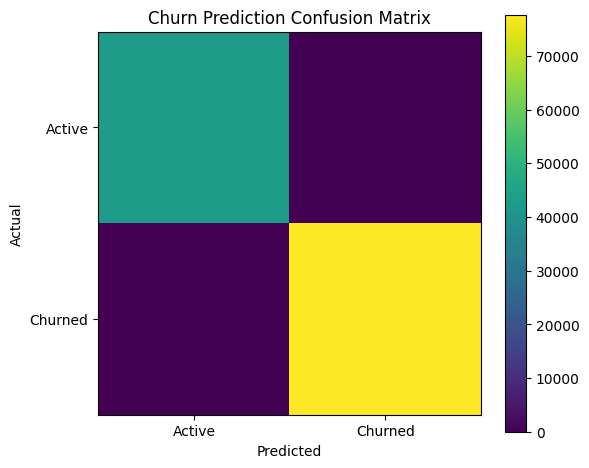

In [240]:
plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title('Churn Prediction Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.xticks([0, 1], ['Active', 'Churned'])
plt.yticks([0, 1], ['Active', 'Churned'])

plt.colorbar()

plt.tight_layout()
plt.show()

# 13. Predictive Churn Modeling

To avoid target leakage, churn prediction is formulated as a
time-based prediction problem.

Customer behavior observed up to the cutoff date is used to predict
whether the customer makes another purchase during the following
180-day period.

Customers with no purchase during the future observation period are
classified as churned.

In [241]:
cutoff_date = pd.Timestamp('2025-09-30')

future_end = pd.Timestamp('2026-03-31')

print("Cutoff date:", cutoff_date)
print("Future observation end:", future_end)

Cutoff date: 2025-09-30 00:00:00
Future observation end: 2026-03-31 00:00:00


In [242]:
historical_df = df[
    df['purchase_date'] <= cutoff_date
].copy()

print("Historical transactions:", len(historical_df))

Historical transactions: 750841


In [243]:
churn_features = historical_df.groupby('user_id').agg(
    Recency=('purchase_date',
             lambda x: (cutoff_date - x.max()).days),
    
    Frequency=('user_id', 'count'),
    
    Monetary=('revenue', 'sum')
)

print(churn_features.head())
print("Customers:", len(churn_features))

         Recency  Frequency  Monetary
user_id                              
U100001       12          2   7551.46
U100003      332          3  12966.04
U100004      140          1  66406.56
U100005      269          1    816.17
U100012      381          3  47441.83
Customers: 509119


In [244]:
future_df = df[
    (df['purchase_date'] > cutoff_date) &
    (df['purchase_date'] <= future_end)
].copy()

print("Future transactions:", len(future_df))
print("Future customers:", future_df['user_id'].nunique())

Future transactions: 249159
Future customers: 217496


In [245]:
future_customers = future_df['user_id'].unique()

churn_features['Churn'] = (
    ~churn_features.index.isin(future_customers)
).astype(int)

print(churn_features['Churn'].value_counts())

Churn
1    386319
0    122800
Name: count, dtype: int64


In [246]:
churn_rate_new = churn_features['Churn'].mean() * 100

print(f"New Churn Rate: {churn_rate_new:.2f}%")

New Churn Rate: 75.88%


In [247]:
print(
    churn_features.groupby('Churn').agg(
        Customers=('Recency', 'size'),
        Avg_Recency=('Recency', 'mean'),
        Avg_Frequency=('Frequency', 'mean'),
        Avg_Monetary=('Monetary', 'mean')
    ).round(2)
)

       Customers  Avg_Recency  Avg_Frequency  Avg_Monetary
Churn                                                     
0         122800       236.40           1.48      14695.15
1         386319       236.41           1.47      14630.10


In [248]:
# Make sure customer IDs have a consistent data type
historical_df['user_id'] = historical_df['user_id'].astype(str)

# Create additional customer-level behavioral features
historical_features = historical_df.groupby(
    'user_id',
    sort=False
).agg(
    Avg_Transaction_Value=('revenue', 'mean'),
    Avg_Rating=('rating', 'mean'),
    Avg_Shipping_Time=('shipping_time_days', 'mean'),
    Return_Rate=('is_returned', 'mean')
)

print(historical_features.head())
print("Feature shape:", historical_features.shape)

         Avg_Transaction_Value  Avg_Rating  Avg_Shipping_Time  Return_Rate
user_id                                                                   
U356787           15336.340000        4.10           5.500000     0.500000
U539898            6231.916667        3.90           2.666667     0.333333
U865179            5589.580000        4.00           5.000000     0.000000
U705397            8779.345000        3.65           3.500000     0.500000
U738720            3047.605000        3.75           3.500000     0.000000
Feature shape: (509119, 4)


In [249]:
print(historical_features.isnull().sum())

Avg_Transaction_Value    0
Avg_Rating               0
Avg_Shipping_Time        0
Return_Rate              0
dtype: int64


In [250]:
churn_features = churn_features.join(
    historical_features,
    how='left'
)

print(churn_features.head())
print("Shape:", churn_features.shape)

         Recency  Frequency  Monetary  Churn  Avg_Transaction_Value  \
user_id                                                               
U100001       12          2   7551.46      1            3775.730000   
U100003      332          3  12966.04      1            4322.013333   
U100004      140          1  66406.56      1           66406.560000   
U100005      269          1    816.17      1             816.170000   
U100012      381          3  47441.83      1           15813.943333   

         Avg_Rating  Avg_Shipping_Time  Return_Rate  
user_id                                              
U100001    4.500000           3.500000          0.0  
U100003    3.800000           5.000000          0.0  
U100004    4.400000           1.000000          0.0  
U100005    3.800000           4.000000          0.0  
U100012    4.333333           4.333333          0.0  
Shape: (509119, 8)


In [251]:
print("Missing values:")
print(churn_features.isnull().sum())

Missing values:
Recency                  0
Frequency                0
Monetary                 0
Churn                    0
Avg_Transaction_Value    0
Avg_Rating               0
Avg_Shipping_Time        0
Return_Rate              0
dtype: int64


In [252]:
feature_columns = [
    'Recency',
    'Frequency',
    'Monetary',
    'Avg_Transaction_Value',
    'Avg_Rating',
    'Avg_Shipping_Time',
    'Return_Rate'
]

X_churn = churn_features[feature_columns]
y_churn = churn_features['Churn']

print("X shape:", X_churn.shape)
print("y shape:", y_churn.shape)

X shape: (509119, 7)
y shape: (509119,)


In [253]:
print("Churn distribution:")
print(y_churn.value_counts())

Churn distribution:
Churn
1    386319
0    122800
Name: count, dtype: int64


In [254]:
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_churn,
    y_churn,
    test_size=0.20,
    random_state=42,
    stratify=y_churn
)

print("Training samples:", X_train_c.shape[0])
print("Testing samples:", X_test_c.shape[0])

Training samples: 407295
Testing samples: 101824


In [255]:
churn_scaler = StandardScaler()

X_train_c_scaled = churn_scaler.fit_transform(X_train_c)
X_test_c_scaled = churn_scaler.transform(X_test_c)

print("Feature scaling completed.")

Feature scaling completed.


In [256]:
from sklearn.linear_model import LogisticRegression

churn_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

churn_model.fit(X_train_c_scaled, y_train_c)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [257]:
y_pred_c = churn_model.predict(X_test_c_scaled)

print("Predictions completed.")
print("Number of predictions:", len(y_pred_c))

Predictions completed.
Number of predictions: 101824


In [258]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy = accuracy_score(y_test_c, y_pred_c)
precision = precision_score(y_test_c, y_pred_c)
recall = recall_score(y_test_c, y_pred_c)
f1 = f1_score(y_test_c, y_pred_c)

print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1-Score :", round(f1, 4))

Accuracy : 0.7588
Precision: 0.7588
Recall   : 1.0
F1-Score : 0.8629


Confusion Matrix:
[[    0 24560]
 [    0 77264]]


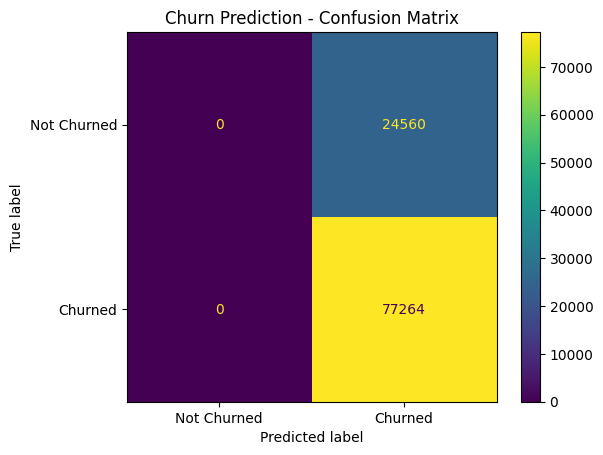

In [259]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test_c, y_pred_c)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Churned", "Churned"]
)

disp.plot()
plt.title("Churn Prediction - Confusion Matrix")
plt.show()

In [260]:
y_prob_c = churn_model.predict_proba(X_test_c_scaled)[:, 1]

print("Minimum probability:", y_prob_c.min())
print("Maximum probability:", y_prob_c.max())
print("Average probability:", y_prob_c.mean())

Minimum probability: 0.7494141121442371
Maximum probability: 0.7712183819282612
Average probability: 0.7587943066827808


In [261]:
from sklearn.ensemble import RandomForestClassifier

rf_churn = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)

rf_churn.fit(X_train_c, y_train_c)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [262]:
y_pred_rf = rf_churn.predict(X_test_c)

print("Random Forest predictions completed.")
print("Number of predictions:", len(y_pred_rf))

Random Forest predictions completed.
Number of predictions: 101824


In [263]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy_rf = accuracy_score(y_test_c, y_pred_rf)
precision_rf = precision_score(y_test_c, y_pred_rf)
recall_rf = recall_score(y_test_c, y_pred_rf)
f1_rf = f1_score(y_test_c, y_pred_rf)

print("Random Forest Results")
print("---------------------")
print("Accuracy :", round(accuracy_rf, 4))
print("Precision:", round(precision_rf, 4))
print("Recall   :", round(recall_rf, 4))
print("F1-Score :", round(f1_rf, 4))


Random Forest Results
---------------------
Accuracy : 0.74
Precision: 0.759
Recall   : 0.963
F1-Score : 0.8489


Random Forest Confusion Matrix:
[[  940 23620]
 [ 2858 74406]]


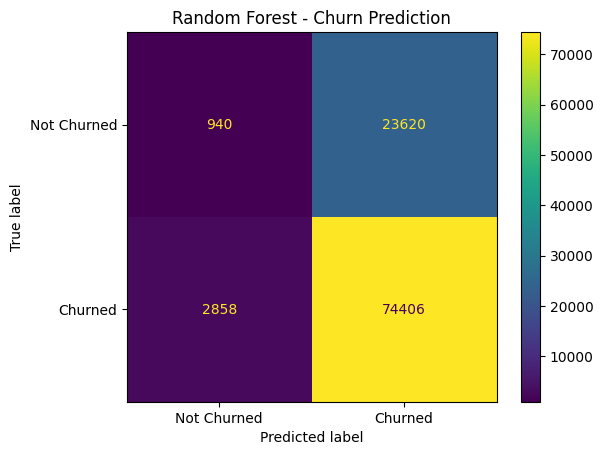

In [264]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_rf = confusion_matrix(y_test_c, y_pred_rf)

print("Random Forest Confusion Matrix:")
print(cm_rf)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["Not Churned", "Churned"]
)

disp.plot()
plt.title("Random Forest - Churn Prediction")
plt.show()

In [265]:
feature_importance = pd.DataFrame({
    'Feature': feature_columns,
    'Importance': rf_churn.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance)

                 Feature  Importance
3  Avg_Transaction_Value    0.279769
2               Monetary    0.279722
0                Recency    0.262093
4             Avg_Rating    0.115168
5      Avg_Shipping_Time    0.045705
6            Return_Rate    0.010087
1              Frequency    0.007456


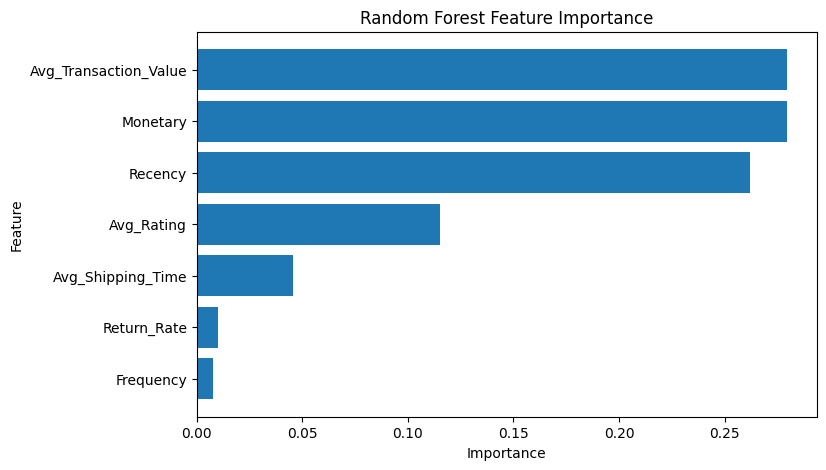

In [266]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.barh(
    feature_importance['Feature'],
    feature_importance['Importance']
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()

plt.show()

## 14. Customer Lifetime Value (CLV) Analysis

Customer Lifetime Value (CLV) estimates the total value a customer contributes based on their purchasing behavior.

In this project, CLV analysis uses customer-level revenue, purchase frequency, average transaction value, and customer lifespan to estimate customer value.

In [267]:
clv = df.groupby('user_id').agg(
    Total_Revenue=('revenue', 'sum'),
    Purchase_Frequency=('user_id', 'count'),
    Avg_Transaction_Value=('revenue', 'mean'),
    Last_Purchase=('purchase_date', 'max'),
    First_Purchase=('purchase_date', 'min')
)

print("CLV dataset shape:", clv.shape)
print("\nFirst 5 customers:")
print(clv.head())

CLV dataset shape: (603815, 5)

First 5 customers:
         Total_Revenue  Purchase_Frequency  Avg_Transaction_Value  \
user_id                                                             
U100001        7551.46                   2            3775.730000   
U100003       12966.04                   3            4322.013333   
U100004       66406.56                   1           66406.560000   
U100005         816.17                   1             816.170000   
U100009        9374.64                   1            9374.640000   

        Last_Purchase First_Purchase  
user_id                               
U100001    2025-09-18     2024-07-11  
U100003    2024-11-02     2024-05-29  
U100004    2025-05-13     2025-05-13  
U100005    2025-01-04     2025-01-04  
U100009    2025-10-08     2025-10-08  


In [268]:
clv['Customer_Lifespan_Days'] = (
    clv['Last_Purchase'] - clv['First_Purchase']
).dt.days

print("Customer lifespan calculated.")

print("\nLifespan statistics:")
print(clv['Customer_Lifespan_Days'].describe())

Customer lifespan calculated.

Lifespan statistics:
count    603815.000000
mean        132.576350
std         190.348215
min           0.000000
25%           0.000000
50%           0.000000
75%         248.000000
max         729.000000
Name: Customer_Lifespan_Days, dtype: float64


In [269]:
# Replace zero-day lifespan with a minimum of 30 days
clv['Adjusted_Lifespan_Days'] = clv['Customer_Lifespan_Days'].clip(lower=30)

# Convert lifespan from days to years
clv['Lifespan_Years'] = clv['Adjusted_Lifespan_Days'] / 365

# Calculate estimated Customer Lifetime Value
clv['CLV'] = (
    clv['Avg_Transaction_Value']
    * clv['Purchase_Frequency']
    * clv['Lifespan_Years']
)

print("CLV calculated successfully.")

print("\nCLV statistics:")
print(clv['CLV'].describe())

CLV calculated successfully.

CLV statistics:
count    603815.000000
mean       9926.461732
std       21195.108682
min           8.469041
25%         262.200822
50%        1280.428767
75%        8258.689836
max      333518.857479
Name: CLV, dtype: float64


In [270]:
q25 = clv['CLV'].quantile(0.25)
q75 = clv['CLV'].quantile(0.75)

clv['CLV_Segment'] = pd.cut(
    clv['CLV'],
    bins=[-float('inf'), q25, q75, float('inf')],
    labels=['Low CLV', 'Medium CLV', 'High CLV']
)

print("CLV segment distribution:")
print(clv['CLV_Segment'].value_counts())

print("\nCLV segment thresholds:")
print("Low CLV: Below", round(q25, 2))
print("Medium CLV:", round(q25, 2), "to", round(q75, 2))
print("High CLV: Above", round(q75, 2))

CLV segment distribution:
CLV_Segment
Medium CLV    301907
Low CLV       150954
High CLV      150954
Name: count, dtype: int64

CLV segment thresholds:
Low CLV: Below 262.2
Medium CLV: 262.2 to 8258.69
High CLV: Above 8258.69


In [271]:
clv_summary = clv.groupby('CLV_Segment', observed=True).agg(
    Customers=('CLV', 'count'),
    Avg_CLV=('CLV', 'mean'),
    Avg_Revenue=('Total_Revenue', 'mean'),
    Avg_Purchase_Frequency=('Purchase_Frequency', 'mean'),
    Avg_Lifespan_Days=('Customer_Lifespan_Days', 'mean')
).reset_index()

print(clv_summary)

  CLV_Segment  Customers       Avg_CLV   Avg_Revenue  Avg_Purchase_Frequency  \
0     Low CLV     150954    132.605626   1609.410394                1.015303   
1  Medium CLV     301907   2240.246373  14264.422047                1.458499   
2    High CLV     150954  35092.697638  35702.274742                2.692244   

   Avg_Lifespan_Days  
0           0.406813  
1          74.597694  
2         380.702817  


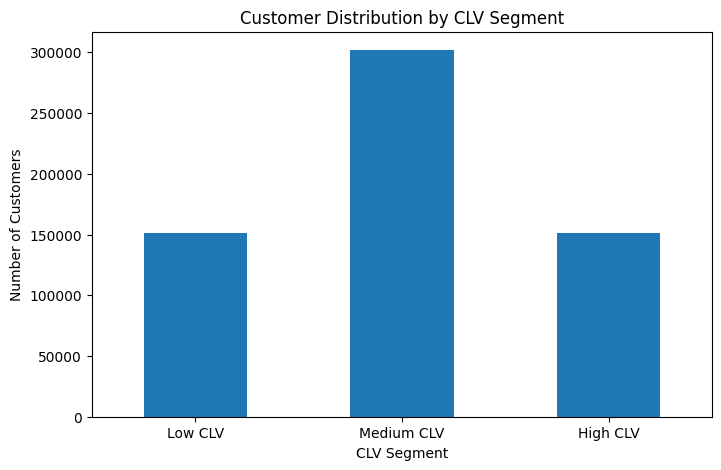

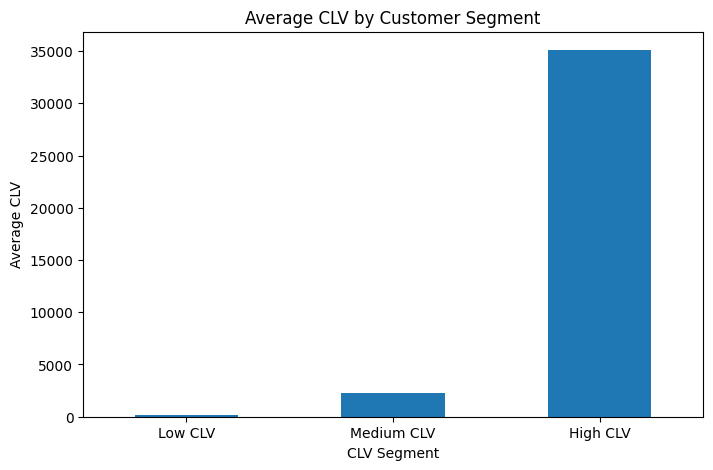

In [272]:
import matplotlib.pyplot as plt

# 1. Customer distribution by CLV segment
plt.figure(figsize=(8, 5))

clv['CLV_Segment'].value_counts().reindex(
    ['Low CLV', 'Medium CLV', 'High CLV']
).plot(kind='bar')

plt.title('Customer Distribution by CLV Segment')
plt.xlabel('CLV Segment')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.show()


# 2. Average CLV by segment
plt.figure(figsize=(8, 5))

clv_summary.set_index('CLV_Segment')['Avg_CLV'].reindex(
    ['Low CLV', 'Medium CLV', 'High CLV']
).plot(kind='bar')

plt.title('Average CLV by Customer Segment')
plt.xlabel('CLV Segment')
plt.ylabel('Average CLV')
plt.xticks(rotation=0)
plt.show()

## 15. Product Recommendation System

The recommendation system suggests products to customers based on their previous purchasing behavior.

In this project, a purchase-based recommendation approach is used because the dataset contains customer IDs and product IDs but does not contain explicit user-product ratings.

The system identifies products that are frequently purchased together and uses these purchase patterns to generate product recommendations.

### Objectives
- Analyze customer-product purchase relationships.
- Identify products frequently purchased together.
- Generate relevant product recommendations.
- Provide a fallback recommendation using popular products when sufficient customer history is unavailable.

### Recommendation Approach
A basic item-based collaborative filtering approach is used. Products purchased by the same customers are analyzed to identify product associations.

The recommendation process consists of:
1. Analyzing customer purchase history.
2. Identifying products purchased by the same customers.
3. Calculating product co-occurrence.
4. Ranking associated products.
5. Recommending the most frequently associated products.

This provides a simple and interpretable recommendation system suitable for the available e-commerce dataset.

In [273]:
user_product_counts = df.groupby('user_id')['product_id'].nunique()

print("Total customers:", user_product_counts.shape[0])
print("Average products per customer:", user_product_counts.mean())
print("Median products per customer:", user_product_counts.median())
print("Maximum products purchased by one customer:", user_product_counts.max())

print("\nCustomers with more than 1 product:")
print((user_product_counts > 1).sum())

Total customers: 603815
Average products per customer: 1.6561248064390584
Median products per customer: 1.0
Maximum products purchased by one customer: 9

Customers with more than 1 product:
274067


## 15.1 Product Co-Occurrence Analysis

Product co-occurrence measures how often two different products are purchased by the same customer.

If two products are frequently purchased by the same customers, they can be considered associated products and may be useful for recommendation.

For example:

Customer A → Product A, Product B  
Customer B → Product A, Product B  
Customer C → Product A, Product C  

Here, Product A and Product B have a strong co-occurrence relationship because both were purchased by multiple customers.

This approach helps generate product recommendations from historical purchase behavior.

In [274]:
# Create customer-product pairs
customer_products = df[['user_id', 'product_id']].drop_duplicates()

print("Unique customer-product pairs:", len(customer_products))
print("Unique customers:", customer_products['user_id'].nunique())
print("Unique products:", customer_products['product_id'].nunique())

Unique customer-product pairs: 999993
Unique customers: 603815
Unique products: 89999


## 15.2 Product Association

To generate product recommendations, products purchased by the same customers are compared.

For each customer, pairs of different products are created from their purchase history. The number of customers who purchased both products is then counted.

Products with higher co-occurrence counts have stronger purchase associations and can be used as recommendations.

In [275]:
from itertools import combinations
from collections import Counter

# Group products purchased by each customer
user_product_lists = customer_products.groupby('user_id')['product_id'].apply(list)

# Count product pairs purchased by the same customers
pair_counts = Counter()

for products in user_product_lists:
    if len(products) > 1:
        for pair in combinations(sorted(set(products)), 2):
            pair_counts[pair] += 1

print("Total product pairs found:", len(pair_counts))

# Display top 10 product pairs
top_pairs = pair_counts.most_common(10)

for pair, count in top_pairs:
    print(pair, "->", count, "customers")

Total product pairs found: 556119
('P39954', 'P84069') -> 2 customers
('P32685', 'P38863') -> 2 customers
('P19632', 'P27906') -> 2 customers
('P11537', 'P94593') -> 2 customers
('P22871', 'P76044') -> 2 customers
('P21658', 'P33067') -> 2 customers
('P21824', 'P46073') -> 2 customers
('P27755', 'P60020') -> 2 customers
('P75022', 'P90060') -> 2 customers
('P45324', 'P57785') -> 2 customers


## 15.3 Product Recommendation Mapping

The product association results are converted into a recommendation mapping.

For each product, associated products are ranked according to the number of customers who purchased both products.

When a strong product association is not available, the system can use popular products as a fallback recommendation.

This hybrid approach helps handle the sparsity of customer purchase history in the dataset.

In [276]:
# Create product-to-product recommendation mapping

product_recommendations = {}

for (product_a, product_b), count in pair_counts.items():
    product_recommendations.setdefault(product_a, []).append(
        (product_b, count)
    )
    product_recommendations.setdefault(product_b, []).append(
        (product_a, count)
    )

# Sort recommendations for each product by co-occurrence count
for product in product_recommendations:
    product_recommendations[product].sort(
        key=lambda x: x[1],
        reverse=True
    )

print("Products with recommendations:", len(product_recommendations))

# Display recommendations for one product
example_product = list(product_recommendations.keys())[0]

print("\nExample product:", example_product)
print("Recommended products:")
print(product_recommendations[example_product][:5])

Products with recommendations: 89954

Example product: P49776
Recommended products:
[('P93848', 1), ('P17908', 1), ('P50137', 1), ('P89045', 1), ('P75152', 1)]


## 15.4 Product Recommendation Function

A recommendation function is created to return products associated with a given product.

The function ranks associated products according to their co-occurrence count and returns the top recommendations.

If the requested product does not have any associated products, the system returns the most frequently purchased products as a fallback.

This makes the recommendation system usable even when customer purchase history is limited.

In [277]:
# Find the most popular products
popular_products = (
    df.groupby('product_id')
      .size()
      .sort_values(ascending=False)
      .index
      .tolist()
)


def recommend_products(product_id, n=5):
    """
    Recommend products based on purchase associations.
    """

    if product_id in product_recommendations:
        recommendations = product_recommendations[product_id]

        # Remove products with very weak associations if possible
        recommendations = sorted(
            recommendations,
            key=lambda x: x[1],
            reverse=True
        )

        return [product for product, count in recommendations[:n]]

    # Popular-product fallback
    return popular_products[:n]


# Test the recommendation system
test_product = 'P49776'

print("Product:", test_product)
print("Recommended Products:")
print(recommend_products(test_product))

Product: P49776
Recommended Products:
['P93848', 'P17908', 'P50137', 'P89045', 'P75152']


## 15.5 Recommendation System Testing

The recommendation system is tested using multiple products from the dataset.

For each selected product, the system returns up to five associated products based on historical purchase patterns.

The system also provides a popularity-based fallback when no product association is available.

Since the dataset has sparse repeat-purchase behavior, recommendations should be interpreted as basic purchase-pattern associations rather than highly personalized recommendations.

In [278]:
# Test recommendations for multiple products

test_products = ['P49776', 'P39954', 'P84069', 'P32685', 'P38863']

for product in test_products:
    print(f"\nProduct: {product}")
    print("Recommended Products:", recommend_products(product, n=5))


Product: P49776
Recommended Products: ['P93848', 'P17908', 'P50137', 'P89045', 'P75152']

Product: P39954
Recommended Products: ['P84069', 'P42695', 'P96297', 'P20429', 'P83272']

Product: P84069
Recommended Products: ['P39954', 'P42695', 'P96297', 'P29971', 'P13240']

Product: P32685
Recommended Products: ['P38863', 'P51483', 'P97944', 'P19462', 'P83952']

Product: P38863
Recommended Products: ['P32685', 'P35830', 'P71530', 'P32792', 'P14323']


# 16. E-Commerce Customer Intelligence Dashboard

This section combines the major analytical results of the project into a dashboard-style view.

The dashboard provides an overall view of sales performance, customer behavior, customer value, churn, and product recommendations.

### Key Areas Covered

- Business and sales performance
- Customer segmentation using RFM and K-Means
- Customer Lifetime Value (CLV)
- Customer churn analysis
- Product recommendations
- Important factors associated with churn

The dashboard helps summarize the analytical findings and provides a consolidated view of e-commerce customer intelligence.

## 16.1 Key Performance Indicators (KPIs)

The following Key Performance Indicators (KPIs) provide an overview of the overall e-commerce business performance.

The KPIs include:

- Total Revenue
- Total Customers
- Total Transactions
- Average Transaction Value
- Return Rate

These indicators provide a quick summary of sales performance and customer activity.

In [279]:
# Calculate key performance indicators

total_revenue = df['revenue'].sum()
total_customers = df['user_id'].nunique()
total_transactions = len(df)
average_transaction_value = df['revenue'].mean()
return_rate = df['is_returned'].mean() * 100

print("========== E-COMMERCE KPIs ==========")
print(f"Total Revenue: ₹{total_revenue:,.2f}")
print(f"Total Customers: {total_customers:,}")
print(f"Total Transactions: {total_transactions:,}")
print(f"Average Transaction Value: ₹{average_transaction_value:,.2f}")
print(f"Return Rate: {return_rate:.2f}%")

========== E-COMMERCE KPIs ==========
Total Revenue: ₹9,938,876,984.90
Total Customers: 603,815
Total Transactions: 1,000,000
Average Transaction Value: ₹9,938.88
Return Rate: 11.60%


## 16.2 Visual KPI Dashboard

The key performance indicators are presented visually to provide a quick overview of the e-commerce business.

The dashboard highlights overall revenue, customer base, transaction volume, average transaction value, and product return rate.

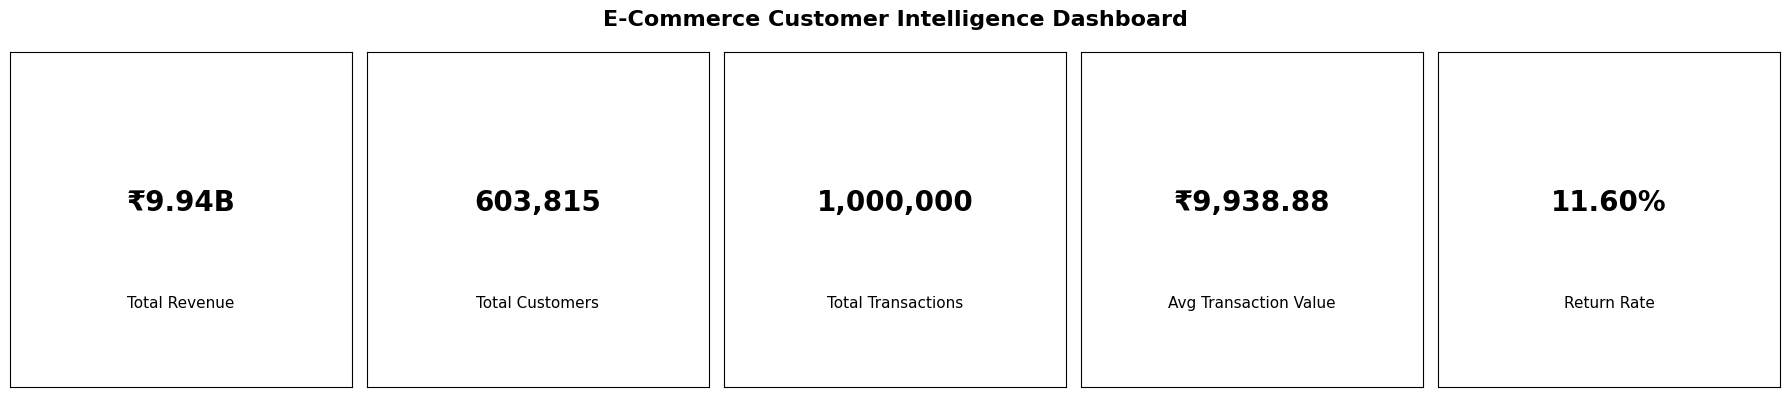

In [280]:
import matplotlib.pyplot as plt

# KPI values
kpi_names = [
    'Total Revenue',
    'Total Customers',
    'Total Transactions',
    'Avg Transaction Value',
    'Return Rate'
]

kpi_values = [
    f'₹{total_revenue/1e9:.2f}B',
    f'{total_customers:,}',
    f'{total_transactions:,}',
    f'₹{average_transaction_value:,.2f}',
    f'{return_rate:.2f}%'
]

fig, axes = plt.subplots(1, 5, figsize=(18, 4))

for ax, name, value in zip(axes, kpi_names, kpi_values):
    ax.text(
        0.5, 0.55, value,
        ha='center',
        va='center',
        fontsize=20,
        fontweight='bold'
    )
    ax.text(
        0.5, 0.25, name,
        ha='center',
        va='center',
        fontsize=11
    )
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_frame_on(True)

plt.suptitle(
    'E-Commerce Customer Intelligence Dashboard',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

## 16.3 Monthly Revenue Trend

The monthly revenue trend shows how total revenue changed over time.

This visualization helps identify periods of higher and lower sales activity and provides an overview of the business revenue pattern across the available dataset period.

In [281]:
# Calculate monthly revenue

monthly_revenue = (
    df.groupby(df['purchase_date'].dt.to_period('M'))['revenue']
      .sum()
      .reset_index()
)

monthly_revenue['purchase_date'] = monthly_revenue['purchase_date'].astype(str)

print(monthly_revenue)

   purchase_date       revenue
0        2024-03  1.388802e+07
1        2024-04  4.096292e+08
2        2024-05  4.207856e+08
3        2024-06  4.051715e+08
4        2024-07  4.217882e+08
5        2024-08  4.202220e+08
6        2024-09  4.039997e+08
7        2024-10  4.235672e+08
8        2024-11  4.118936e+08
9        2024-12  4.220663e+08
10       2025-01  4.247258e+08
11       2025-02  3.787897e+08
12       2025-03  4.230896e+08
13       2025-04  4.033051e+08
14       2025-05  4.200312e+08
15       2025-06  4.056538e+08
16       2025-07  4.213890e+08
17       2025-08  4.265546e+08
18       2025-09  3.999008e+08
19       2025-10  4.222367e+08
20       2025-11  4.056734e+08
21       2025-12  4.281423e+08
22       2026-01  4.214767e+08
23       2026-02  3.812453e+08
24       2026-03  4.236515e+08


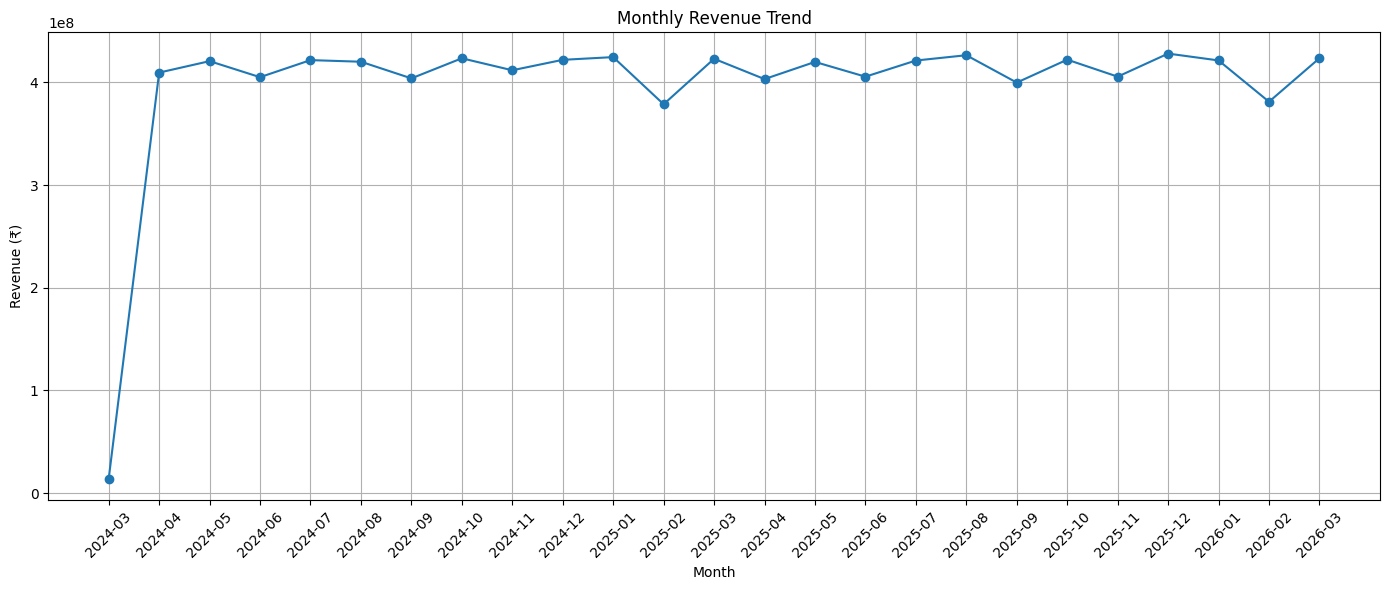

In [282]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_revenue['purchase_date'],
    monthly_revenue['revenue'],
    marker='o'
)

plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue (₹)')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

## 16.4 Revenue by Product Category

Revenue is analyzed across different product categories to identify the contribution of each category to overall business revenue.

This analysis helps understand category-level sales performance and identify the major revenue-generating categories.

In [283]:
# Calculate revenue by category

category_revenue = (
    df.groupby('category')['revenue']
      .sum()
      .sort_values(ascending=False)
      .reset_index()
)

print(category_revenue)

      category       revenue
0  Electronics  6.579048e+09
1         Home  1.529978e+09
2       Sports  1.124849e+09
3       Beauty  3.759517e+08
4     Clothing  3.290504e+08


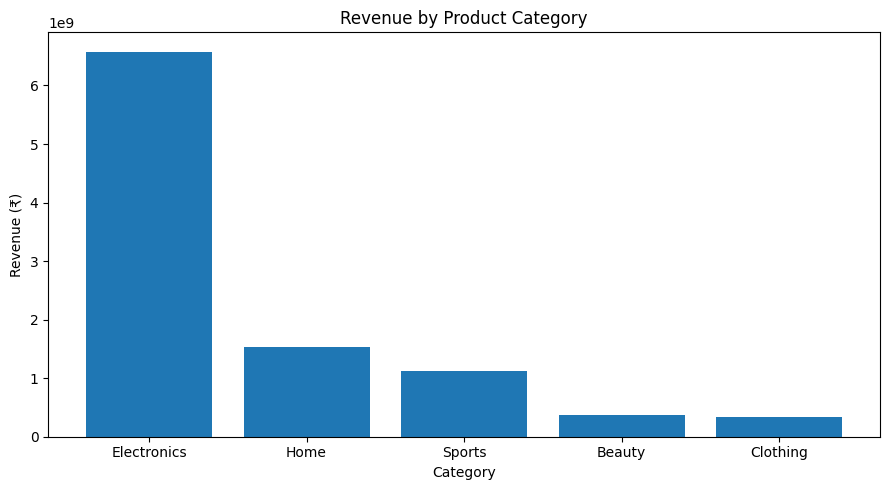

In [284]:
plt.figure(figsize=(9, 5))

plt.bar(
    category_revenue['category'],
    category_revenue['revenue']
)

plt.title('Revenue by Product Category')
plt.xlabel('Category')
plt.ylabel('Revenue (₹)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 16.5 Customer Segmentation Analysis

Customer segmentation is performed using RFM analysis and K-Means clustering.

The customers are divided into four behavioral segments based on their recency, purchase frequency, and monetary value:

- Recent Active Customers
- At-Risk High-Value Customers
- Dormant Low-Value Customers
- Frequent High-Value Customers

The segment distribution helps understand the composition of the customer base and identify different customer behavior patterns.

In [285]:
# Customer segment distribution

segment_counts = (
    rfm['Segment']
    .value_counts()
    .reindex([
        'Recent Active Customers',
        'At-Risk High-Value Customers',
        'Dormant Low-Value Customers',
        'Frequent High-Value Customers'
    ])
)

print(segment_counts)

Segment
Recent Active Customers           78850
At-Risk High-Value Customers     133987
Dormant Low-Value Customers      186969
Frequent High-Value Customers    204009
Name: count, dtype: int64


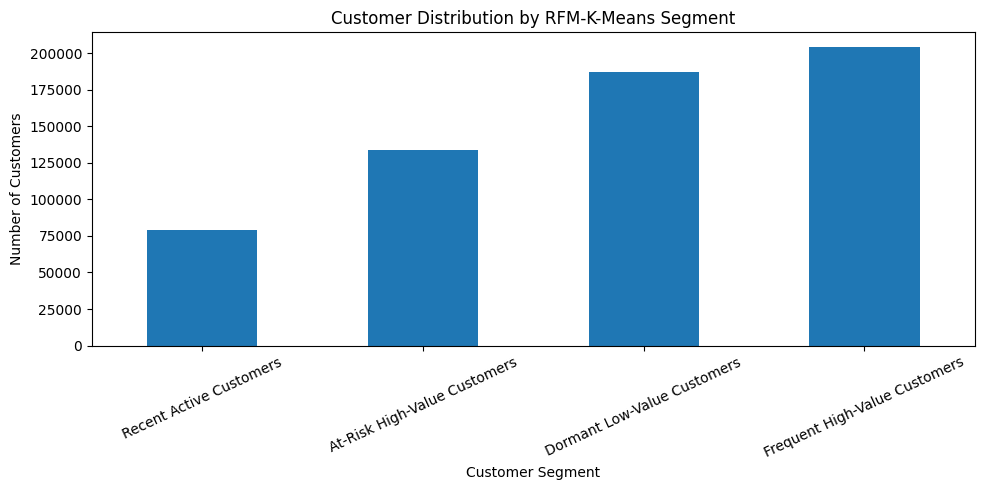

In [286]:
plt.figure(figsize=(10, 5))

segment_counts.plot(kind='bar')

plt.title('Customer Distribution by RFM-K-Means Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Number of Customers')
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

## 16.6 Customer Lifetime Value (CLV) Analysis

Customer Lifetime Value (CLV) estimates the value generated by customers based on their purchasing behavior, purchase frequency, transaction value, and observed customer lifespan.

Customers are divided into three CLV segments:

- Low CLV
- Medium CLV
- High CLV

The analysis helps compare customer value across different groups.

In [287]:
# Display CLV segment summary

clv_dashboard = clv_summary[
    [
        'CLV_Segment',
        'Customers',
        'Avg_CLV',
        'Avg_Revenue',
        'Avg_Purchase_Frequency',
        'Avg_Lifespan_Days'
    ]
]

print(clv_dashboard)

  CLV_Segment  Customers       Avg_CLV   Avg_Revenue  Avg_Purchase_Frequency  \
0     Low CLV     150954    132.605626   1609.410394                1.015303   
1  Medium CLV     301907   2240.246373  14264.422047                1.458499   
2    High CLV     150954  35092.697638  35702.274742                2.692244   

   Avg_Lifespan_Days  
0           0.406813  
1          74.597694  
2         380.702817  


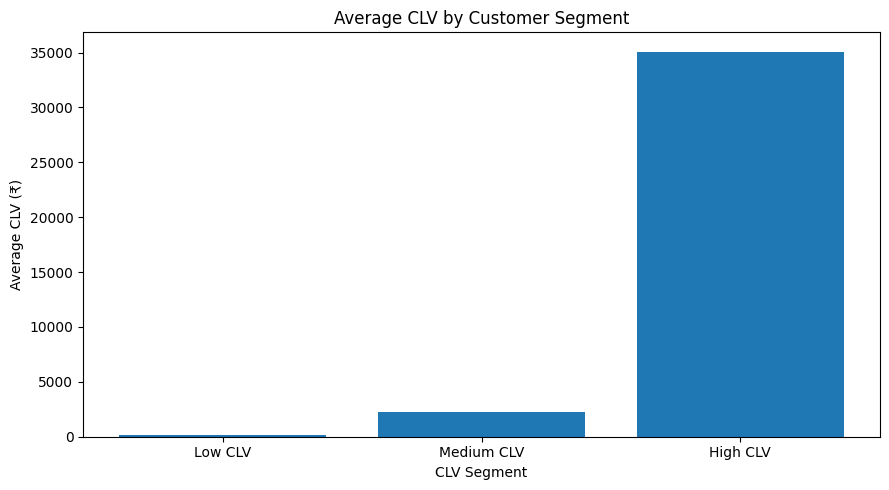

In [288]:
plt.figure(figsize=(9, 5))

plt.bar(
    clv_dashboard['CLV_Segment'].astype(str),
    clv_dashboard['Avg_CLV']
)

plt.title('Average CLV by Customer Segment')
plt.xlabel('CLV Segment')
plt.ylabel('Average CLV (₹)')
plt.tight_layout()
plt.show()

## 16.7 Customer Churn Analysis

Customer churn analysis identifies customers who did not make any purchase during the future observation period.

In this project, churn is defined using a time-based approach:
- Churn = 1: No purchase between October 1, 2025 and March 31, 2026
- Churn = 0: At least one purchase during this period

This analysis helps identify the proportion of customers who became inactive.

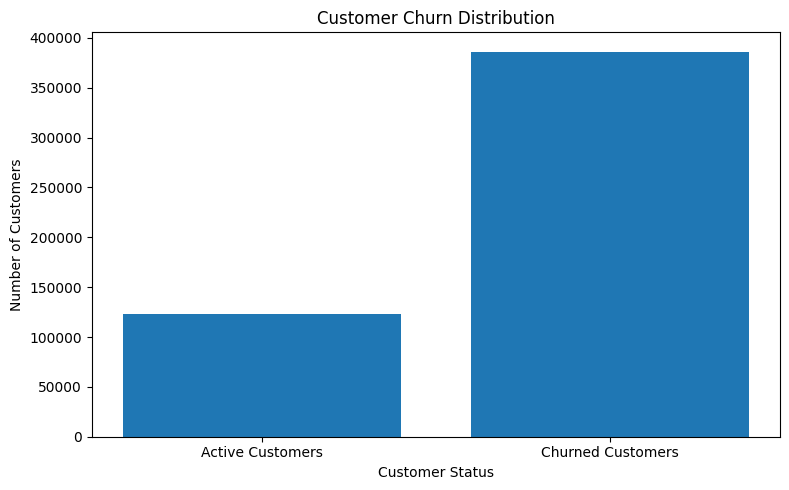

Active Customers: 122800
Churned Customers: 386319
Churn Rate: 75.88%


In [289]:
# Churn distribution
churn_counts = churn_features['Churn'].value_counts().sort_index()

churn_labels = ['Active Customers', 'Churned Customers']

plt.figure(figsize=(8, 5))

plt.bar(
    churn_labels,
    [
        churn_counts.get(0, 0),
        churn_counts.get(1, 0)
    ]
)

plt.title('Customer Churn Distribution')
plt.xlabel('Customer Status')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()

print("Active Customers:", churn_counts.get(0, 0))
print("Churned Customers:", churn_counts.get(1, 0))
print(
    "Churn Rate:",
    f"{churn_features['Churn'].mean() * 100:.2f}%"
)

## 16.8 Churn Prediction Model and Important Factors

A Random Forest classification model was used to identify customers who are likely to churn based on their historical purchasing behavior.

The model uses customer-level features such as:
- Recency
- Frequency
- Monetary value
- Average transaction value
- Average rating
- Average shipping time
- Return rate

Feature importance is used to understand which variables contributed most to the model's predictions.

In [290]:
# Random Forest feature importance

feature_importance = pd.DataFrame({
    'Feature': feature_columns,
    'Importance': rf_churn.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance)

                 Feature  Importance
3  Avg_Transaction_Value    0.279769
2               Monetary    0.279722
0                Recency    0.262093
4             Avg_Rating    0.115168
5      Avg_Shipping_Time    0.045705
6            Return_Rate    0.010087
1              Frequency    0.007456


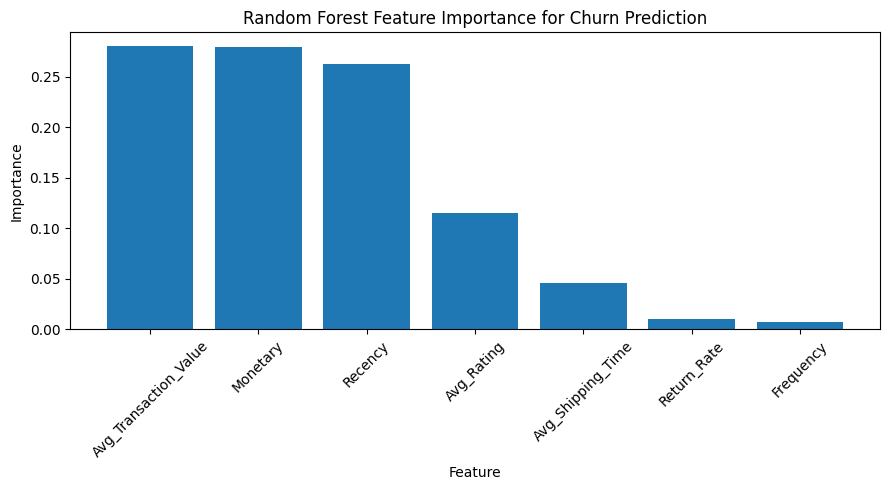

In [291]:
plt.figure(figsize=(9, 5))

plt.bar(
    feature_importance['Feature'],
    feature_importance['Importance']
)

plt.title('Random Forest Feature Importance for Churn Prediction')
plt.xlabel('Feature')
plt.ylabel('Importance')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 16.9 Product Recommendation System

The recommendation system provides product suggestions based on customer purchase patterns.

An item-based co-occurrence approach is used to identify products that are frequently purchased by the same customers.

For customers or products with limited purchase history, popular products are used as a fallback recommendation.

The system demonstrates how customer purchase behavior can be used to generate basic product recommendations.

In [292]:
# Display example product recommendations

test_products = ['P49776', 'P39954', 'P84069']

for product in test_products:
    recommendations = recommend_products(product, n=5)

    print(f"\nRecommendations for {product}:")
    print(recommendations)


Recommendations for P49776:
['P93848', 'P17908', 'P50137', 'P89045', 'P75152']

Recommendations for P39954:
['P84069', 'P42695', 'P96297', 'P20429', 'P83272']

Recommendations for P84069:
['P39954', 'P42695', 'P96297', 'P29971', 'P13240']


## 16.10 Key Insights from the E-Commerce Analysis

The major insights obtained from the analysis are:

- The dataset contains 1,000,000 transactions from 603,815 customers.
- Total revenue generated is approximately ₹9.94 billion.
- Electronics generated the highest revenue among the product categories.
- RFM and K-Means analysis identified four customer segments: Recent Active, At-Risk High-Value, Dormant Low-Value, and Frequent High-Value Customers.
- The Frequent High-Value segment has the highest average purchase frequency and monetary value.
- The time-based churn analysis identified a churn rate of 75.88% in the defined observation cohort.
- Customer Lifetime Value analysis divided customers into Low, Medium, and High CLV groups.
- The recommendation system generated product suggestions using customer-product purchase patterns.
- Random Forest feature importance showed that transaction value, monetary value, and recency were among the most influential features for churn prediction.

# 17. Project Conclusion

The E-Commerce Customer Intelligence and Analytics System successfully analyzes customer purchasing behavior using data analytics and machine learning techniques.

The project performed data preprocessing, exploratory data analysis, RFM analysis, K-Means customer segmentation, churn analysis, Customer Lifetime Value estimation, and product recommendation.

The analysis provides insights into sales performance, customer value, purchasing behavior, customer segments, and churn patterns.

The recommendation system demonstrates how purchase history can be used to generate product suggestions, while the churn model identifies important behavioral factors associated with customer inactivity.

Overall, the project provides a consolidated analytical framework that can help understand e-commerce customer behavior and support data-driven business analysis.

# 18. Export Data for Power BI

The processed analytical datasets are exported as CSV files for integration
with Microsoft Power BI.

The exported datasets include transaction-level data, customer segmentation,
Customer Lifetime Value, and customer churn information.

In [293]:
# Export transaction data
df.to_csv('/kaggle/working/transactions.csv', index=False)

# Export customer segmentation data
customer_segments = rfm.reset_index()
customer_segments.to_csv(
    '/kaggle/working/customer_segments.csv',
    index=False
)

# Export CLV data
customer_clv = clv.reset_index()
customer_clv.to_csv(
    '/kaggle/working/customer_clv.csv',
    index=False
)

# Export churn data
customer_churn = churn_features.reset_index()
customer_churn.to_csv(
    '/kaggle/working/customer_churn.csv',
    index=False
)

print("All Power BI files exported successfully!")

All Power BI files exported successfully!


In [294]:
import os

print("Files in /kaggle/working/:")

for file in os.listdir('/kaggle/working/'):
    print(file)


Files in /kaggle/working/:
customer_segments.csv
.virtual_documents
transactions.csv
customer_churn.csv
customer_clv.csv


In [295]:
print("df:", 'df' in globals())
print("rfm:", 'rfm' in globals())
print("clv:", 'clv' in globals())
print("churn_features:", 'churn_features' in globals())

df: True
rfm: True
clv: True
churn_features: True


In [296]:
import os

# 1. Main transaction data
df.to_csv('/kaggle/working/transactions.csv', index=False)

# 2. Customer segmentation
customer_segments = rfm.reset_index()
customer_segments.to_csv(
    '/kaggle/working/customer_segments.csv',
    index=False
)

# 3. Customer Lifetime Value
customer_clv = clv.reset_index()
customer_clv.to_csv(
    '/kaggle/working/customer_clv.csv',
    index=False
)

# 4. Customer churn
customer_churn = churn_features.reset_index()
customer_churn.to_csv(
    '/kaggle/working/customer_churn.csv',
    index=False
)

print("Export completed!\n")

# Verify files
for file in [
    'transactions.csv',
    'customer_segments.csv',
    'customer_clv.csv',
    'customer_churn.csv'
]:
    path = '/kaggle/working/' + file
    
    if os.path.exists(path):
        size_mb = os.path.getsize(path) / (1024**2)
        print(f"✓ {file} — {size_mb:.2f} MB")
    else:
        print(f"✗ {file} — NOT FOUND")

Export completed!

✓ transactions.csv — 134.83 MB
✓ customer_segments.csv — 41.19 MB
✓ customer_clv.csv — 60.12 MB
✓ customer_churn.csv — 23.80 MB
